# vti-02 — Measure

`metadata.hera.policy` — scientific record: append new cells; never edit or
delete executed ones. (Who *executes* a measure cell is set by the session
mode — see the brief.)

Confirm each `# <-- verify` (rig: addresses) and `# <-- validate` (device:
operating limits, wiring) line at bring-up. Cells marked **PATTERN** /
**PROPOSAL** carry `<PLACEHOLDER>` values — review before running.

## Setup

In [1]:
import os
import time

import numpy as np
import scipy.constants as cst

import qcodes
from qcodes import validators
from qcodes.instrument_drivers.stanford_research import SR830
from qcodes.instrument_drivers.tektronix.Keithley_2400 import Keithley_2400

import sweep
from sweep import interruptible_sleep
from gui.qt_progress import QtProgress
sweep.set_progress(QtProgress())

from hera.analysis import GateCalibration, field_invB
from sharpelab_nb.closeout import read_state
from sharpelab_nb.constants import VTI
from sharpelab_nb.keithley import assert_keithley_state, normalize_keithley_state
from sharpelab_nb.thermometry import assert_thermometry_live, temperature_from_logfiles

from drivers.FastBi1K5 import FastBi1K5
from drivers.Lakeshore_335 import Lakeshore_335
from drivers.SRS_DC205 import SRS_DC205

In [2]:
main_dir = os.getcwd()
sweep.set_basedir(os.path.join(main_dir, "data"))
main_dir

'C:\\Users\\DGG\\VTI_local_data\\zack\\20260824-vti-02'

# Connect Instruments

## Magnet

In [3]:
magnet = FastBi1K5('magnet', '192.168.0.10')  # <-- verify address
magnet.status()

Connected to: Fast-Bi-1K5 Magnet Controller
---------- Magnet Status ----------
Field:               : 0.006 Tesla
Current:             : 0.046 A
Voltage:             : 0.000 V
Output Enabled       : True
Persistent Switch On : True
Loop Mode            : CC
Update Mode          : NORMAL
-----------------------------------


## Lakeshore

In [4]:
# heater: LS335 control only (setpoints / ranges / heater power). The lakeshore
# worker (VTI Monitor launcher) is the sole GPIB master on the LS335; per-point
# temperature is read from its logfiles, never over GPIB. fp() these params.
heater = Lakeshore_335('l335_3', 'GPIB0::10::INSTR')

# Liveness gate, hard: rig card cadence 5 s, guard >= 2-3 periods; the legacy
# worker writes ~30 s and a dead one leaves a plausible frozen T on the page.
assert_thermometry_live("T_sample", VTI.temp_logfile_candidates["T_sample"], max_age=15, max_period=12)
assert_thermometry_live("T_vaporizer", VTI.temp_logfile_candidates["T_vaporizer"], max_age=15, max_period=12)

T_sample = temperature_from_logfiles("T_sample", VTI.temp_logfile_candidates["T_sample"])
T_vaporizer = temperature_from_logfiles("T_vaporizer", VTI.temp_logfile_candidates["T_vaporizer"])

print(f"Sample:    {T_sample()} K")
print(f"Vaporizer: {T_vaporizer()} K")

Connected to: LSCI 335 (serial:LSA2FM7/#######, firmware:1.4) in 0.56s
T_sample: VTI_sample.txt live — age 3s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 3s, period 5s
Sample:    1.171 K
Vaporizer: 0.948 K


## Lock-ins

In [5]:
sr0 = SR830('sr0', "GPIB0::22::INSTR")  # <-- verify — current channel (Ithaco preamp output)
sr1 = SR830('sr1', "GPIB0::14::INSTR")  # <-- verify — also the AC drive source
sr2 = SR830('sr2', "GPIB0::19::INSTR")  # <-- verify
sr3 = SR830('sr3', "GPIB0::18::INSTR")  # <-- verify

Connected to: Stanford_Research_Systems SR830 (serial:s/n45620, firmware:ver1.07) in 0.10s
Connected to: Stanford_Research_Systems SR830 (serial:s/n83412, firmware:ver1.07) in 0.08s


C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr0 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch2_databuffer on instrument sr0 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr1 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.p

Connected to: Stanford_Research_Systems SR830 (serial:s/n41639, firmware:ver1.07) in 0.10s
Connected to: Stanford_Research_Systems SR830 (serial:s/n93552, firmware:ver1.07) in 0.09s


C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch2_databuffer on instrument sr2 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr3 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch2_databuffer on instrument sr3 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(


## Keithleys

In [6]:
k_2400_tg = Keithley_2400('k_2400_tg', 'GPIB0::1::INSTR')  # <-- verify address — top-gate Keithley
k_2400_tg.volt.step = 0.005   # driver-side ramp pacing — software only, dies with the kernel
# Read-first: verify mode/ranges/NPLC/averaging/0 V against the expected table.
# Writes nothing; raises with the deltas on any mismatch (resolve before handoff).
assert_keithley_state(k_2400_tg, rangei=1.05e-6)

Connected to: KEITHLEY INSTRUMENTS INC. 2400 (serial:1225634, firmware:C30   Mar 17 2006 09:29:29/A02  /K/J) in 0.03s
k_2400_tg: state verified, no writes — mode=VOLT, rangev=21.0, rangei=1.05e-06, nplci=1.0, volt=+0.0000


In [7]:
k_2400_bg = Keithley_2400('k_2400_bg', 'GPIB0::24::INSTR')  # <-- verify address — back-gate Keithley
k_2400_bg.volt.step = 0.005   # driver-side ramp pacing — software only, dies with the kernel
# Read-first: verify mode/ranges/NPLC/averaging/0 V against the expected table.
# Writes nothing; raises with the deltas on any mismatch (resolve before handoff).
assert_keithley_state(k_2400_bg, rangei=1.05e-6)

Connected to: KEITHLEY INSTRUMENTS INC. 2400 (serial:0734554, firmware:C17   Jul 16 1999 15:20:40/A02  /G/F) in 0.02s
k_2400_bg: state verified, no writes — mode=VOLT, rangev=21.0, rangei=1.05e-06, nplci=1.0, volt=+0.0000


## DC205 (Si gate)

In [8]:
dc205 = SRS_DC205("dc205", "ASRL7::INSTR")  # <-- verify address — Si-gate DC205
# Si window is ±25 V ⇒ DC205 must be on its ±100 V range (RNGE 2). Range
# changes require output OFF (front panel) — surface a mismatch, don't force it.
print(f"range code: {dc205.voltage_range()} (need 2 = ±100 V)")
print(f"output on:  {dc205.output()}")
dc205.ramp_rate = 0.5  # V/s — Si dielectric pacing; consent-gated    # <-- validate

Connected to: Stanford_Research_Systems DC205 (serial:s/n20500514, firmware:ver1.80) in 0.03s
range code: 2 (need 2 = ±100 V)
output on:  1


In [9]:
# slot: gate-bindings — role aliases (k_tg/k_bg/k_si) from the device card's
# Gate stack section (which instrument drives which gate). Each value
# `# <-- validate`.

# Gate role aliases (role aliases: k_tg / k_bg / k_si):
k_tg = k_2400_tg   # top gate  <- Keithley 2400 (fast axis k_tg.volt)   # <-- validate
k_bg = k_2400_bg   # back gate <- Keithley 2400                          # <-- validate
# Si gate <- the driver's ramped parameter: set ramps at dc205.ramp_rate,
# get reads back VOLT?. Data column 'dc205_smart_voltage'. No current readback.
k_si = dc205.smart_voltage   # <-- validate

# SAFETIES

Run immediately after instrument bring-up, before any sweep.

In [10]:
# slot: gate-validators — operating limits from the device card's gate-
# operating-limits table; commit EXACTLY the card numbers. Each value
# `# <-- validate`. Instrument-level fences go on the RAW instruments
# (k_2400_tg / k_2400_bg / dc205); direct calls bypass the role-alias wrapper.
TG_MIN, TG_MAX = -0.3, +1.0    # top gate (k_2400_tg), V     # <-- validate
BG_MIN, BG_MAX = -1.3, +2.0    # back gate (k_2400_bg), V    # <-- validate
SI_MIN, SI_MAX = -25.0, +25.0  # Si gate (dc205), V          # <-- validate
k_2400_tg.volt.vals = validators.Numbers(TG_MIN, TG_MAX)
k_2400_bg.volt.vals = validators.Numbers(BG_MIN, BG_MAX)
dc205.smart_voltage.vals = validators.Numbers(SI_MIN, SI_MAX)  # k_si sets go through this
dc205.voltage.vals = validators.Numbers(SI_MIN, SI_MAX)  # instrument-level: ramp_voltage sets via dc205.voltage, so this fences ramps too

# Limit lists for sanitize_tg_bg()
tg_lims, bg_lims = [TG_MIN, TG_MAX], [BG_MIN, BG_MAX]

# Session field cap — machine-enforced: magnet.field is a qcodes Parameter,
# so this validator rejects any magnet.field(target) with |B| > B_SESSION_CAP
# before any hardware traffic (and the non-blocking start_field_ramp re-checks
# it too). (Driver max_field_T = 14.0 remains as backstop.)
B_SESSION_CAP = 10.0  # Tesla    # <-- validate (session cap from card/brief)
magnet.field.vals = validators.Numbers(-B_SESSION_CAP, B_SESSION_CAP)

# Temperature setpoint cap — session cap from the card (also the typo guard
# vs sample_setpoint(3000)). The real safe T/B envelope is a rig-card item.
T_SESSION_CAP = 100.0  # K    # <-- validate (session cap from card/brief)
heater.sample_setpoint.vals = validators.Numbers(0, T_SESSION_CAP)
heater.vaporizer_setpoint.vals = validators.Numbers(0, T_SESSION_CAP)

# Helpers

In [11]:
def spoints(a, b, c):
    return np.linspace(a, b, c)


def sanitize_tg_bg(vtg_vec, vbg_vec, tg_lims, bg_lims):
    """
    Given a list of tg and bg voltages, removes any points which are outside tg_lims and bg_lims
    """
    vtg_new_vec = []
    vbg_new_vec = []
    for ind in range(len(vtg_vec)):
        vtg, vbg = vtg_vec[ind], vbg_vec[ind]
        if vtg < tg_lims[0] or vtg > tg_lims[1] or vbg < bg_lims[0] or vbg > bg_lims[1]:
            pass
        else:
            vtg_new_vec.append(vtg)
            vbg_new_vec.append(vbg)
    return np.array(vtg_new_vec), np.array(vbg_new_vec)

In [12]:
# slot: geometry — gate-stack thicknesses from the device card's Gate-stack
# geometry (geometry prior — establish the session's gate calibration before
# trusting derived scales). Each value `# <-- validate`.
t_tg = 9.5e-9   # top-gate hBN thickness, m    # <-- validate
t_bg = 11e-9    # back-gate hBN thickness, m    # <-- validate
t_bgSiO2 = 0    # SiO2 term, m — zero for a graphite back gate    # <-- validate

# Session gate calibration. cal.n_D(V_tg, V_bg) -> (n [m^-2], D [V/m]);
# set n_offset / D_offset from the session's gate calibration once live.
cal = GateCalibration.from_thicknesses(t_tg, t_bg, t_bgSiO2)

# Measurement config

In [13]:
# slot: meas-config — sr0_gain + channel/contact assignments from the device
# card's Measurement setup (current channel + gain, provided contact
# configuration). Each value `# <-- validate`. Always set 'comments' per run —
# structured, current, no inherited text. Lock-in state (amplitude, freq,
# sens, tau) is NOT recorded here — sweep snapshots followed instruments
# live at each run start; bias_channel tells hera-watch where the drive is.
meas_config = {
    "source": "T_0",  # drive injection contact    # <-- validate
    "sr0": "drain current on B_3",  # <-- validate
    "sr0_gain": -1e6,  # ithaco gain    # <-- validate
    "sr1": "B_1 - B_2",  # <-- validate
    "sr2": "n.c.",  # <-- validate
    "sr3": "n.c.",  # <-- validate
    "bias_resistor": 100e6,
    "bias_channel": "sr1",  # drive lock-in; I_bias = its live amplitude / bias_resistor (auto-snapshotted)    # <-- validate
    "sample_temperature:": T_sample(),  # file-based (worker logfile), not in instrument snapshots; key verbatim (trailing ':') to match this cooldown's metadata
    "Si (V)": dc205.voltage(),  # not snapshotted unless followed — re-run this cell after moving Si
    "comments": "<SET PER RUN>",
}

## Contacts — hardwired (no mux this cooldown)

No QSwitch/ContactMux in the loop: contact roles are fixed at the breakout.
The map below is documentation from the device card's provided contact
configuration; changing a pair is operator work at the breakout, not software.

In [14]:
# slot: contact-map — hardwired role -> contact map from the device card's
# provided contact configuration. Documentation only (no mux to drive);
# each value `# <-- validate`.
WIRING = {  # <-- validate (from card provided contact configuration)
    "source": "T_0", "drain": "B_3",
    "sr1+": "B_1", "sr1-": "B_2",
    "sr2": "n.c.",
    "sr3": "n.c.",
}

# State capture

Restorable acquisition + gate state, read at bring-up. Feeds
`close_out(restore=state0)` at session end. Field is the close-out
decision — never captured for blind restore.

In [15]:
# Restorable state only — field is the close-out decision, never restored blind.
state0 = read_state(
    drive_V=sr1.amplitude, drive_Hz=sr1.frequency,
    sr0_sens=sr0.sensitivity, sr0_tau=sr0.time_constant, sr0_slope=sr0.filter_slope,
    sr1_sens=sr1.sensitivity, sr1_tau=sr1.time_constant, sr1_slope=sr1.filter_slope,
    sr2_sens=sr2.sensitivity, sr2_tau=sr2.time_constant, sr2_slope=sr2.filter_slope,
    sr3_sens=sr3.sensitivity, sr3_tau=sr3.time_constant, sr3_slope=sr3.filter_slope,
    tg_nplci=k_2400_tg.nplci, bg_nplci=k_2400_bg.nplci,
    V_tg=k_2400_tg.volt, V_bg=k_2400_bg.volt,
    V_si=dc205.smart_voltage,
)

drive_V : 1.0
drive_Hz : 13.777
sr0_sens : 0.02
sr0_tau : 0.3
sr0_slope : 24
sr1_sens : 2e-06
sr1_tau : 0.3
sr1_slope : 24
sr2_sens : 0.0001
sr2_tau : 0.1
sr2_slope : 24
sr3_sens : 0.005
sr3_tau : 0.1
sr3_slope : 24
tg_nplci : 1.0
bg_nplci : 1.0
V_tg : 0.0
V_bg : 0.0
V_si : 0.0


# Close-out

Authored at session end per the brief's Close-out step
(+ rig variant) — the ask comes from the session brief; the field endpoint
is an explicit decision. `state0` above feeds `restore=`.

# HERA — session start (2026-08-24)

## HERA — E1 kernel-binding probe (read-only)

Brief [VERIFY] item: *"the first E1 execute is a read-only namespace probe that
confirms it is bound to the operator's instrument-carrying kernel."* This is that
probe and nothing more — it reads `os`/`globals()`/the qcodes instrument registry
and writes to no instrument. It must print `PROBE: BOUND` before the VERIFY cell
below is executed.


In [16]:
# HERA — E1 kernel-binding probe. READ-ONLY: no instrument writes, no sets,
# no ramps, no sweeps. Confirms this execute landed in the operator's
# instrument-carrying kernel (the one that ran Setup + SAFETIES) and not a
# fresh or unrelated one. Must pass before VERIFY runs.
import os
import qcodes

print(f"pid              : {os.getpid()}")
print(f"cwd              : {os.getcwd()}")
try:
    print(f"sweep BASEDIR    : {getattr(sweep, 'BASEDIR', '<unset>')}")
except Exception as e:
    print(f"sweep BASEDIR    : <error {e!r}>")

_g = globals()
_need = [
    "magnet", "heater", "sr0", "sr1", "sr2", "sr3",
    "k_2400_tg", "k_2400_bg", "dc205", "k_tg", "k_bg", "k_si",
    "T_sample", "T_vaporizer", "state0", "cal", "meas_config", "WIRING",
    "tg_lims", "bg_lims", "B_SESSION_CAP", "T_SESSION_CAP",
]
_missing = [n for n in _need if n not in _g]
print(f"namespace missing: {_missing if _missing else 'none'}")

try:
    _live = sorted(qcodes.Instrument._all_instruments)
except Exception as e:
    _live = f"<error {e!r}>"
print(f"live instruments : {_live}")

try:
    print(f"state0           : {len(state0)} keys, V_tg={state0.get('V_tg')} "
          f"V_bg={state0.get('V_bg')} V_si={state0.get('V_si')}")
except Exception as e:
    print(f"state0           : <error {e!r}>")

print("PROBE: BOUND" if not _missing else f"PROBE: NOT BOUND — missing {_missing}")


pid              : 36068
cwd              : C:\Users\DGG\VTI_local_data\zack\20260824-vti-02
sweep BASEDIR    : None
namespace missing: none
live instruments : ['dc205', 'k_2400_bg', 'k_2400_tg', 'l335_3', 'magnet', 'sr0', 'sr1', 'sr2', 'sr3']
state0           : <error AttributeError("'StateRecord' object has no attribute 'get'")>
PROBE: BOUND


## HERA — VERIFY (read-only): session-start checklist + autonomy verdict

Plan step **P0**. The session brief's `[VERIFY]` list, one check per line, ending in
the machine-readable verdict the E1 grant keys on: `VERIFY: ALL GREEN` or
`VERIFY: FAIL <item>`. **Read-only by construction** — every statement is a get;
nothing is set, ramped, or swept, so this is safe to run at any time.

Checks: magnet at 0 T (measured readback, plus persistent switch + output);
every SAFETIES validator compared **numerically** against the device card's
gate-operating-limits table and the session B / T caps; thermometry worker live
(logfile age + cadence, so a frozen-but-plausible T cannot pass) and sample T
holding 1.2–1.3 K; both heater ranges 0 with the vaporizer tracking base; contacts
hardwired — no QSwitch/ContactMux anywhere in the kernel and `WIRING` equal to the
card's provided configuration; DC205 on RNGE 2, output on, sitting at 0 V.

Below the verdict-bearing checks is an **informational** block (not gating): each
lock-in's sensitivity / tau / slope with its live X, Y, R and full-scale fraction,
the drive amplitude to `I_bias`, the measured drain current, the zero-gate Rxx, and
both gate-leakage currents. Those numbers size the sweep dwell and catch a lock-in
that will rail the moment a gate moves — and the rig card notes tau/slope live
nowhere on disk except the bring-up record, so they are captured here.

**Precondition to running this:** the kernel-binding probe cell above must have
printed `PROBE: BOUND`.


In [17]:
# HERA — VERIFY. READ-ONLY BY CONSTRUCTION: every statement below is a get.
# No parameter is set, no ramp is issued, no sweep is started. Walks the
# session brief's [VERIFY] checklist; the LAST printed line is the
# machine-readable verdict the autonomy grant keys on.
_fails = []


def chk(name, ok, detail):
    print(f"[{'PASS' if ok else 'FAIL'}] {name:<24} {detail}")
    if not ok:
        _fails.append(name)


# --- 1. magnet at 0 T (measured readback, never the last set) -------------
try:
    _B = magnet.field()
    _st = magnet._status()
    _psw, _out = magnet.persistent_switch_on(), magnet.output_enabled()
    chk("magnet-at-zero", abs(_B) <= 0.02 and bool(_psw) and bool(_out),
        f"field()={_B:+.4f} T | status={_st} | psw={_psw} output={_out}")
except Exception as e:
    chk("magnet-at-zero", False, repr(e))

# --- 2. SAFETIES committed == device-card operating limits ----------------
# Device card, Gate-operating-limits table + session caps. Compared as numbers.
_CARD = {
    "k_2400_tg.volt":            (k_2400_tg.volt,            -0.3,   +1.0),
    "k_2400_bg.volt":            (k_2400_bg.volt,            -1.3,   +2.0),
    "dc205.smart_voltage":       (dc205.smart_voltage,      -25.0,  +25.0),
    "dc205.voltage":             (dc205.voltage,            -25.0,  +25.0),
    "magnet.field":              (magnet.field,             -10.0,  +10.0),
    "heater.sample_setpoint":    (heater.sample_setpoint,     0.0,  100.0),
    "heater.vaporizer_setpoint": (heater.vaporizer_setpoint,  0.0,  100.0),
}
for _name, (_p, _lo, _hi) in _CARD.items():
    try:
        _v = _p.vals
        _got = (getattr(_v, "_min_value", None), getattr(_v, "_max_value", None))
        _ok = isinstance(_v, validators.Numbers) and _got == (_lo, _hi)
        chk(f"safeties:{_name.split('.')[-1]}", _ok,
            f"{_name}.vals = {_v} (card: [{_lo}, {_hi}])")
    except Exception as e:
        chk(f"safeties:{_name.split('.')[-1]}", False, repr(e))
# k_si must be the same object the validator was committed on.
chk("safeties:k_si-binding", k_si is dc205.smart_voltage,
    f"k_si is dc205.smart_voltage -> {k_si is dc205.smart_voltage}")

# --- 3. thermometry live + base T holding ---------------------------------
_Ts = _Tv = float("nan")
try:
    assert_thermometry_live("T_sample", VTI.temp_logfile_candidates["T_sample"],
                            max_age=15, max_period=12)
    assert_thermometry_live("T_vaporizer", VTI.temp_logfile_candidates["T_vaporizer"],
                            max_age=15, max_period=12)
    _Ts, _Tv = T_sample(), T_vaporizer()
    chk("base-T", 1.10 <= _Ts <= 1.40, f"T_sample = {_Ts:.3f} K (expect 1.2-1.3 K)")
except Exception as e:
    chk("base-T", False, repr(e))

# --- 4. heaters off, vaporizer tracking base ------------------------------
try:
    _sr, _vr = int(heater.sample_range()), int(heater.vaporizer_range())
    chk("heaters-off", _sr == 0 and _vr == 0,
        f"sample_range={_sr} vaporizer_range={_vr} (both must be 0)")
    chk("vaporizer-tracks-base", _Tv < 2.0,
        f"T_vaporizer = {_Tv:.3f} K (T_sample = {_Ts:.3f} K)")
except Exception as e:
    chk("heaters-off", False, repr(e))

# --- 5. contacts hardwired, no mux this cooldown --------------------------
_CARD_WIRING = {"source": "T_0", "drain": "B_3",
                "sr1+": "B_1", "sr1-": "B_2", "sr2": "n.c.", "sr3": "n.c."}
try:
    _mux_absent = not ({"mux", "qswitch", "contact_mux"} & set(globals()))
    _live_names = set(qcodes.Instrument._all_instruments)
    _no_qsw = not any(("qsw" in n.lower()) or ("switch" in n.lower()) for n in _live_names)
    chk("contacts-hardwired", _mux_absent and _no_qsw and WIRING == _CARD_WIRING,
        f"mux absent={_mux_absent and _no_qsw} | WIRING matches card={WIRING == _CARD_WIRING} | {WIRING}")
    chk("meas-config-channels",
        meas_config["source"] == "T_0" and meas_config["sr0_gain"] == -1e6
        and meas_config["sr1"] == "B_1 - B_2" and meas_config["bias_resistor"] == 100e6
        and meas_config["bias_channel"] == "sr1",
        f"source={meas_config['source']} sr0={meas_config['sr0']} "
        f"sr0_gain={meas_config['sr0_gain']:g} sr1={meas_config['sr1']} "
        f"Rbias={meas_config['bias_resistor']:g}")
except Exception as e:
    chk("contacts-hardwired", False, repr(e))

# --- 6. DC205 on +/-100 V range, output on, at 0 V ------------------------
try:
    _rng = int(dc205.voltage_range())
    _outp = int(dc205.output())
    _vsi = float(dc205.voltage())
    chk("dc205-state", _rng == 2 and _outp == 1 and abs(_vsi) <= 1e-3,
        f"range={_rng} (need 2 = +/-100 V) output={_outp} voltage={_vsi:+.4f} V "
        f"ramp_rate={dc205.ramp_rate} V/s")
except Exception as e:
    chk("dc205-state", False, repr(e))

# --- informational: acquisition state (recorded, NOT gating) --------------
print("\n--- informational: acquisition state (not gating) ---")
_lv = {}
for _n, _srN in (("sr0", sr0), ("sr1", sr1), ("sr2", sr2), ("sr3", sr3)):
    try:
        _s, _t, _f = _srN.sensitivity(), _srN.time_constant(), _srN.filter_slope()
        _x, _y, _r = _srN.X(), _srN.Y(), _srN.R()
        _lv[_n] = dict(sens=_s, tau=_t, slope=_f, X=_x, Y=_y, R=_r)
        print(f"{_n}: sens={_s:<9.3g} tau={_t:<6g}s slope={_f:g}dB/oct  "
              f"X={_x:+.4g}  Y={_y:+.4g}  R={_r:.4g}  fs=|R|/sens={abs(_r) / _s:6.2f}")
    except Exception as e:
        print(f"{_n}: <error {e!r}>")
try:
    _amp, _frq = sr1.amplitude(), sr1.frequency()
    _Ibias = _amp / meas_config["bias_resistor"]
    _Imeas = _lv["sr0"]["X"] / meas_config["sr0_gain"]
    print(f"drive: {_amp} V @ {_frq} Hz through {meas_config['bias_resistor']:.3g} ohm "
          f"-> I_bias = {_Ibias * 1e9:.3f} nA")
    print(f"sr0 -> I_measured = {_Imeas * 1e9:+.4f} nA "
          f"({100 * abs(_Imeas) / _Ibias:.1f}% of I_bias)")
    if abs(_Imeas) > 1e-13:
        print(f"sr1 (B_1-B_2) at V_tg=V_bg=V_si=0 -> Rxx = {_lv['sr1']['X'] / _Imeas:+.4g} ohm")
    print(f"gate leakage: TG {k_2400_tg.curr() * 1e12:+.1f} pA | "
          f"BG {k_2400_bg.curr() * 1e12:+.1f} pA")
    _hot = [n for n, d in _lv.items() if n in ("sr0", "sr1") and abs(d["R"]) / d["sens"] > 0.9]
    if _hot:
        print(f"ADVISORY (not a VERIFY gate): {_hot} at >90% of full scale — "
              f"sensitivity needs raising before any sweep. Operator ask.")
except Exception as e:
    print(f"<informational block error {e!r}>")

# --- verdict (must be the last line) --------------------------------------
print()
print("VERIFY: ALL GREEN" if not _fails else f"VERIFY: FAIL {','.join(_fails)}")


[PASS] magnet-at-zero           field()=+0.0063 T | status={'voltage': 9.25e-05, 'field': 0.006329698630136986, 'output_enabled': True, 'persistent_switch_on': True, 'loop_mode': 'CC', 'update_mode': 'NORMAL'} | psw=True output=True
[PASS] safeties:volt            k_2400_tg.volt.vals = <Numbers -0.3<=v<=1.0> (card: [-0.3, 1.0])
[PASS] safeties:volt            k_2400_bg.volt.vals = <Numbers -1.3<=v<=2.0> (card: [-1.3, 2.0])
[PASS] safeties:smart_voltage   dc205.smart_voltage.vals = <Numbers -25.0<=v<=25.0> (card: [-25.0, 25.0])
[PASS] safeties:voltage         dc205.voltage.vals = <Numbers -25.0<=v<=25.0> (card: [-25.0, 25.0])
[PASS] safeties:field           magnet.field.vals = <Numbers -10.0<=v<=10.0> (card: [-10.0, 10.0])
[PASS] safeties:sample_setpoint heater.sample_setpoint.vals = <Numbers 0<=v<=100.0> (card: [0.0, 100.0])
[PASS] safeties:vaporizer_setpoint heater.vaporizer_setpoint.vals = <Numbers 0<=v<=100.0> (card: [0.0, 100.0])
[PASS] safeties:k_si-binding    k_si is dc205.smart_

sr2: sens=0.0001    tau=0.1   s slope=24dB/oct  X=+2.012e-07  Y=-6.557e-07  R=6.743e-07  fs=|R|/sens=  0.01
sr3: sens=0.005     tau=0.1   s slope=24dB/oct  X=+0  Y=-4.768e-07  R=2.384e-07  fs=|R|/sens=  0.00
drive: 1.0 V @ 13.777 Hz through 1e+08 ohm -> I_bias = 10.000 nA
sr0 -> I_measured = +9.8649 nA (98.6% of I_bias)
sr1 (B_1-B_2) at V_tg=V_bg=V_si=0 -> Rxx = +205 ohm


gate leakage: TG -101.3 pA | BG +24.4 pA
ADVISORY (not a VERIFY gate): ['sr1'] at >90% of full scale — sensitivity needs raising before any sweep. Operator ask.

VERIFY: ALL GREEN


## HERA — P1 / Gate C: back-gate liveness, find the CNP

> **12:11** · gatec-liveness: 1D V\_bg -1.30 to +2.00 V, 133 pts @ 25 mV, V\_tg=0, V\_si=0, B=0, T=base, delay 2.1 s (7 tau); read sr0 drain current (sr1 railed at 2 uV sens) · **ETA ~12:17** (≈6 min)

Plan step **P1** (`hera_scratch/plan.md`) and the brief's Gate C — a cheap liveness
check on the provided contact configuration, inside the committed limits. Nothing
expensive runs until this passes.

**Why this cut.** VERIFY says the contacts are alive from the source side already:
I_measured = 9.86 nA is 98.6 % of the 10 nA bias, so T_0 → B_3 is carrying and the
device is far below the 100 MΩ bias resistor. What I do not have is where the charge
neutrality point sits — the brief withholds it, and every later step (the gate map's
window, the fixed-D cuts, the fan's density axis) is anchored on it. A single 1D
V_bg cut at V_tg = 0 across the whole committed back-gate range sweeps
Δn ≈ 5.0 × 10¹² cm⁻² on the geometry prior, which should bracket the CNP unless the
intrinsic doping is larger than that.

**Read the current channel, not Rxx, this run.** sr1 is railed — sens 2 µV against a
2.022 µV reading, fs = 1.01 — so its Rxx number (205 Ω) is a lower bound, not a
measurement. sr0 is at fs 0.50 and cannot rail going forward (the drain current only
*falls* as the device approaches the CNP), so the two-terminal conductance dip is the
valid CNP locator here. sr1 is still followed and plotted so the sensitivity fix shows
up the moment it lands. Ask is out to the operator: sr1 sens → 1 mV, and τ → 0.1 s on
sr0+sr1.

**Dwell is compliant, not bent.** τ = 0.3 s at 24 dB/oct ⇒ 7τ = 2.1 s, which is what
`delay` is set to. That is the whole reason the τ ask matters: it prices this 133-point
cut at ~5 min and the coarse gate map at ~2 h.

**Preconditions asserted before anything moves:** thermometry worker live (age +
cadence, so a frozen logfile cannot pass), T_sample in the base window, |B| ≤ 0.02 T
(this cell never touches the magnet), V_si = 0 (silent inherited axis), and — the one
that would silently waste the run — **both Keithley source outputs ON**, since a gate
set into a disabled output is inert and would look like a featureless trace.

**Checkpoint:** first rows watched live for railing, a dead channel, or leakage
excess; the run is short enough that the periodic checkpoint is the completion read.


T_sample: VTI_sample.txt live — age 5s, period 5s
pre: T_sample = 1.170 K          (expect 1.10-1.40)
pre: B        = +0.0063 T         (expect |B| <= 0.02; this cell does not move the magnet)
pre: V_si     = +0.0000 V        (expect 0; this cell does not move Si)
pre: outputs  = TG True / BG True   (both must be ON or gate sets are inert)
2026-08-24 12:11:58,352 [INFO] Starting sweep with ID 0


2026-08-24 12:11:58,353 [INFO] Minimum duration 0h 4m 39s


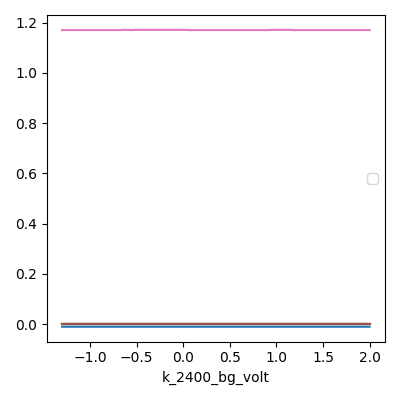

2026-08-24 12:16:54,933 [INFO] Completed in 0h 4m 56s


2026-08-24 12:16:54,934 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260824-vti-02\data\0\data.tsv.gz



run id = 0   C:\Users\DGG\VTI_local_data\zack\20260824-vti-02\data\0\data.tsv.gz
post: V_bg = +2.0000 V   V_tg = +0.0000 V   T_sample = 1.170 K   B = +0.0063 T


In [18]:
# HERA — plan step P1 (Gate C): back-gate liveness sweep, B = 0, base T.
# ---------------------------------------------------------------- preconditions
# State this cell ASSUMES but does not set. Under E1 there is no operator glance
# before the run, so these are the go/no-go. Stop on mismatch, before hardware moves.
assert_thermometry_live("T_sample", VTI.temp_logfile_candidates["T_sample"],
                        max_age=15, max_period=12)
_Ts = T_sample()
_B = magnet.field()                 # measured readback, never the last set
_Vsi = dc205.voltage()              # Si is a silent inherited axis this cell never touches
_out_tg, _out_bg = k_2400_tg.output(), k_2400_bg.output()
print(f"pre: T_sample = {_Ts:.3f} K          (expect 1.10-1.40)")
print(f"pre: B        = {_B:+.4f} T         (expect |B| <= 0.02; this cell does not move the magnet)")
print(f"pre: V_si     = {_Vsi:+.4f} V        (expect 0; this cell does not move Si)")
print(f"pre: outputs  = TG {_out_tg} / BG {_out_bg}   (both must be ON or gate sets are inert)")
assert 1.10 <= _Ts <= 1.40, f"T_sample {_Ts} K outside base window"
assert abs(_B) <= 0.02, f"B = {_B} T, expected ~0"
assert abs(_Vsi) <= 1e-3, f"V_si = {_Vsi} V, expected 0"
assert bool(_out_tg) and bool(_out_bg), "Keithley source output OFF — gate sets would be inert"

# ------------------------------------------------------------------ fixed axis
k_tg.volt(0.000)                    # this cell owns TG: park it (paced at volt.step = 5 mV)

# ------------------------------------------------------------------ the sweep
DATA_DIR = os.path.join(main_dir, "data")   # explicit: sweep.BASEDIR is a stale re-export
VBG = spoints(-1.30, 2.00, 133)             # 25 mV steps, full committed BG range
DELAY = 2.1                                 # 7*tau at tau = 0.3 s, 24 dB/oct — compliant, not bent

meas_config["comments"] = ("gatec-liveness — 1D V_bg over the full committed range at "
                           "V_tg = 0, locating the CNP from the two-terminal drain current")
meas_config["sample_temperature:"] = _Ts
meas_config["Si (V)"] = _Vsi

s = sweep.AsyncStation(meas_config, basedir=DATA_DIR)
s.fp(sr0.X).fp(sr0.Y).fp(sr1.X).fp(sr1.Y)      # raw volts: gain lives in measurement_config
s.fp(k_2400_tg.curr).fp(k_2400_bg.curr).fp(T_sample)
s.add_comment("gatec-liveness")
s.add_comment(
    "1D V_bg -1.300 -> +2.000 V, 133 pts @ 25 mV | V_tg = 0.000 V | V_si = 0.000 V | "
    "B = 0 T | T = base (~1.17 K) | delay 2.1 s = 7*tau (tau 0.3 s, 24 dB/oct) | "
    "I_bias 10.0 nA (1.0 V / 100 MOhm @ 13.777 Hz) | "
    "sr0 = drain current T_0 -> B_3, Ithaco gain -1e6 (VALID) | "
    "sr1 = Vxx B_1-B_2, sens 2 uV and RAILED at fs 1.01 — read sr0 this run | "
    "TG/BG leakage baseline at 0 V: -101 pA / +24 pA"
)
s.plot(k_bg.volt, [sr0.X, sr0.Y, sr1.X, sr1.Y,
                   k_2400_tg.curr, k_2400_bg.curr, T_sample])

res = s.sweep(k_bg.volt, VBG, delay=DELAY)
print(f"\nrun id = {res.id}   {res.datapath}")
print(f"post: V_bg = {k_bg.volt():+.4f} V   V_tg = {k_tg.volt():+.4f} V   "
      f"T_sample = {T_sample():.3f} K   B = {magnet.field():+.4f} T")


## HERA — P1b: re-range sr1, re-run the back-gate cut

> **12:20** · bg-cut: sr1 sens 2uV->1mV + sr0/sr1 tau 0.3->0.1 s (operator-authorized), then 1D V\_bg +2.00 to -1.30 V, 133 pts @ 25 mV, V\_tg=0, V\_si=0, B=0, T=base, delay 0.7 s (7 tau) · **ETA ~12:24** (≈4 min)

Plan step **P1** (second pass). Run 0 passed Gate C but clipped the one channel that
matters. This cell fixes the acquisition and repeats the cut; it costs ~2.5 min and
gates the ~45 min map that follows, so it runs first.

**What run 0 established.** The drain current traces a clean, symmetric dip centred at
**V_bg = −0.200 V** at V_tg = 0 — that is the CNP, and on the geometry prior it puts the
intrinsic doping at n_offset ≈ +3.0 × 10¹¹ cm⁻² (slightly electron-doped) with the CNP
sitting at D/ε₀ ≈ +0.027 V/nm, i.e. essentially zero field. Leakage is clean: both gate
currents are flat and voltage-independent (TG −100 pA, BG +25 pA offsets), and the ~100 pA
spikes appear **simultaneously on both independent gates**, which is pickup or a read
collision, not leakage — real gate leakage cannot be common-mode across two separate
Keithleys.

**Why sr1 must be re-ranged.** Rxx clipped at 218 Ω (fs 1.09) over 30 % of the sweep,
so the CNP peak height is unmeasured. The drain current cannot substitute: the 100 MΩ
bias resistor defines the current, so a device going 100 Ω → 100 kΩ moves I by ~0.1 %.
New sensitivity **1 mV** = 100 kΩ of Rxx headroom at 10 nA bias, which covers a flat-band
CNP; the metallic end (65 Ω, 0.65 µV) sits 60 dB down, well inside an SR830's reserve.

**Why τ drops to 0.1 s.** Compliant dwell is 7τ, so 0.3 s costs 2.1 s/pt and prices the
coarse map at ~1.9 h; 0.1 s costs 0.7 s/pt and prices it at ~45 min. At the 13.777 Hz
drive a 100 ms 24 dB/oct filter still puts 2f (27.6 Hz) about 99 dB down. It is set on
**sr0 as well as sr1** — the dwell is gated by the slowest channel, so re-ranging only
sr1 would buy nothing. Both are instrument-configuration writes on lock-in inputs; no
validator, gate limit, field cap or T cap is touched.

**One systematic this run will let me size.** R₂ₜ off-CNP is ~0.75 MΩ against a
four-terminal Rxx of ~100 Ω, so the **contacts dominate the two-terminal resistance**
(~0.4 MΩ each), and they roughly double through the CNP. That matters because the SR830
input is 10 MΩ: ~0.8 MΩ of series probe resistance divides Vxx down by ~7 %, and worse
if the probe contacts go strongly resistive at the CNP. So absolute Rxx carries a
systematic that grows near the CNP. `sr1_Y` (the quadrature) is followed and plotted
precisely so I can watch for the phase drift that would flag it.

**Reverse direction** (+2.00 → −1.30 V): starts where run 0 left the gate, and buys a
hysteresis check against run 0 for free.

**Checkpoint:** first digest rows for clipping and for the new noise floor at the
metallic end — if 1 mV proves too coarse there, that shows up immediately and costs
2 min, not 45.


T_sample: VTI_sample.txt live — age 2s, period 6s
pre: T_sample = 1.170 K          (expect 1.10-1.40)
pre: B        = +0.0063 T         (expect |B| <= 0.02; this cell does not move the magnet)
pre: V_si     = +0.0000 V        (expect 0; this cell does not move Si)
pre: V_tg     = +0.0000 V        (expect 0.000, parked by run 0)
pre: V_bg     = +2.0000 V        (expect +2.000, where run 0 ended)
pre: outputs  = TG True / BG True


post-set sr0: sens=0.02 V  tau=0.1 s  slope=24 dB/oct


post-set sr1: sens=0.001 V  tau=0.1 s  slope=24 dB/oct


live at V_bg=+2.000: sr1 X = +0.5960 uV (fs 0.0006)   sr0 X = -0.009889 V
2026-08-24 12:20:15,527 [INFO] Starting sweep with ID 1


2026-08-24 12:20:15,528 [INFO] Minimum duration 0h 1m 33s


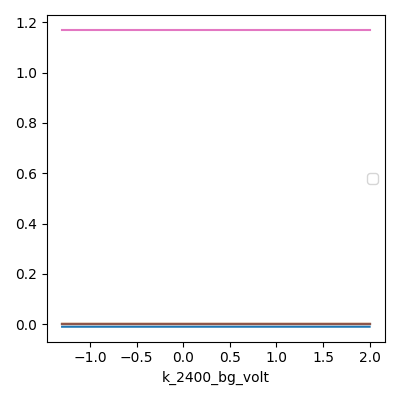

2026-08-24 12:22:04,203 [INFO] Completed in 0h 1m 48s


2026-08-24 12:22:04,204 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260824-vti-02\data\1\data.tsv.gz



run id = 1   C:\Users\DGG\VTI_local_data\zack\20260824-vti-02\data\1\data.tsv.gz
post: V_bg = -1.3000 V   V_tg = +0.0000 V   T_sample = 1.170 K   B = +0.0063 T


In [19]:
# HERA — P1b: acquisition re-range (operator-authorized), then the back-gate cut
# re-run with an unclipped Rxx. Supersedes run 0 for every Rxx number.
# ---------------------------------------------------------------- preconditions
assert_thermometry_live("T_sample", VTI.temp_logfile_candidates["T_sample"],
                        max_age=15, max_period=12)
_Ts = T_sample()
_B = magnet.field()
_Vsi = dc205.voltage()
_Vtg, _Vbg = k_tg.volt(), k_bg.volt()
_out_tg, _out_bg = k_2400_tg.output(), k_2400_bg.output()
print(f"pre: T_sample = {_Ts:.3f} K          (expect 1.10-1.40)")
print(f"pre: B        = {_B:+.4f} T         (expect |B| <= 0.02; this cell does not move the magnet)")
print(f"pre: V_si     = {_Vsi:+.4f} V        (expect 0; this cell does not move Si)")
print(f"pre: V_tg     = {_Vtg:+.4f} V        (expect 0.000, parked by run 0)")
print(f"pre: V_bg     = {_Vbg:+.4f} V        (expect +2.000, where run 0 ended)")
print(f"pre: outputs  = TG {_out_tg} / BG {_out_bg}")
assert 1.10 <= _Ts <= 1.40, f"T_sample {_Ts} K outside base window"
assert abs(_B) <= 0.02, f"B = {_B} T, expected ~0"
assert abs(_Vsi) <= 1e-3, f"V_si = {_Vsi} V, expected 0"
assert abs(_Vtg) <= 1e-3, f"V_tg = {_Vtg} V, expected 0"
assert bool(_out_tg) and bool(_out_bg), "Keithley source output OFF — gate sets would be inert"

# ------------------------------------------------- acquisition re-range
# Operator-authorized (Zack, this session): set sr1 sensitivity + time constant
# from the notebook, values at my discretion. Rationale on the markdown cell.
# NOT a safety surface — no validator, limit or cap is touched here.
sr1.sensitivity(1e-3)        # 2 uV -> 1 mV : 100 kOhm of Rxx headroom at 10 nA
sr0.time_constant(0.1)       # 0.3 s -> 0.1 s (dwell is gated by the SLOWEST channel)
sr1.time_constant(0.1)
for _n, _srN in (("sr0", sr0), ("sr1", sr1)):
    print(f"post-set {_n}: sens={_srN.sensitivity():.3g} V  tau={_srN.time_constant():g} s  "
          f"slope={_srN.filter_slope():g} dB/oct")
assert sr1.sensitivity() == 1e-3 and sr0.time_constant() == 0.1 and sr1.time_constant() == 0.1, \
    "lock-in re-range did not read back as commanded"
interruptible_sleep(5)       # let the new filters settle before the first point
print(f"live at V_bg={_Vbg:+.3f}: sr1 X = {sr1.X() * 1e6:+.4f} uV "
      f"(fs {abs(sr1.R()) / sr1.sensitivity():.4f})   sr0 X = {sr0.X():+.6f} V")

# ------------------------------------------------------------------ the sweep
DATA_DIR = os.path.join(main_dir, "data")
VBG = spoints(2.00, -1.30, 133)   # REVERSE of run 0: starts where the gate sits, and
                                  # gives a hysteresis check against run 0 for free
DELAY = 0.7                       # 7*tau at the new tau = 0.1 s — compliant, not bent

meas_config["comments"] = ("bg-cut — back-gate cut at V_tg = 0 with sr1 re-ranged to 1 mV; "
                           "locates the CNP in Rxx and sets the Rxx scale for the gate map")
meas_config["sample_temperature:"] = _Ts
meas_config["Si (V)"] = _Vsi

s = sweep.AsyncStation(meas_config, basedir=DATA_DIR)
s.fp(sr0.X).fp(sr0.Y).fp(sr1.X).fp(sr1.Y)
s.fp(k_2400_tg.curr).fp(k_2400_bg.curr).fp(T_sample)
s.add_comment("bg-cut")
s.add_comment(
    "1D V_bg +2.000 -> -1.300 V (reverse of run 0), 133 pts @ 25 mV | V_tg = 0.000 V | "
    "V_si = 0.000 V | B = 0 T | T = base (~1.17 K) | delay 0.7 s = 7*tau (tau 0.1 s, 24 dB/oct) | "
    "I_bias 10.0 nA (1.0 V / 100 MOhm @ 13.777 Hz) | "
    "sr0 = drain current T_0 -> B_3, Ithaco gain -1e6, sens 20 mV | "
    "sr1 = Vxx B_1-B_2, sens NOW 1 mV (was 2 uV and clipped above 218 ohm in run 0) | "
    "run 0 put the CNP at V_bg = -0.200 V from the drain-current dip; this run measures "
    "the Rxx peak there without clipping"
)
s.plot(k_bg.volt, [sr0.X, sr0.Y, sr1.X, sr1.Y,
                   k_2400_tg.curr, k_2400_bg.curr, T_sample])

res = s.sweep(k_bg.volt, VBG, delay=DELAY)
print(f"\nrun id = {res.id}   {res.datapath}")
print(f"post: V_bg = {k_bg.volt():+.4f} V   V_tg = {k_tg.volt():+.4f} V   "
      f"T_sample = {T_sample():.3f} K   B = {magnet.field():+.4f} T")


## HERA — P2: coarse (n, D) gate map — the primary stacking discriminator

> **12:25** · gate-map: 2D megasweep, slow V\_bg -1.30 to +0.40 V x35 @ 50 mV, fast V\_tg -0.30 to +1.00 V x66 @ 20 mV, 2310 pts, V\_si=0, B=0, T=base, fast/slow delay 0.7 s; CNP line spans D/eps0 +0.320 to -0.067 V/nm · **ETA ~13:07** (≈42 min)

Plan step **P2**. This is the measurement the call rests on. ABAB, ABCA and ABCB differ
most cheaply in **what a displacement field does to the charge-neutral point**: a Bernal
tetralayer is a band-overlapped semimetal that stays conducting under D; a rhombohedral
one opens a large single-particle gap that grows with |D| and drives R_CNP up by orders
of magnitude; a mixed ABCB stack gaps too, but — lacking inversion symmetry — not
symmetrically about D = 0. One map answers all three.

**What P1 already fixed.** Run 1 puts the CNP at **V_bg = −0.250 V at V_tg = 0**, i.e.
n_offset ≈ +3.8 × 10¹¹ cm⁻² and a crossing at D/ε₀ ≈ +0.034 V/nm — effectively zero
field. So the CNP line is `V_bg = −1.158·V_tg − 0.250` on the geometry prior, and the
peak Rxx there is **297 Ω**. Hysteresis between the up- and down-sweeps is 50 mV, one
grid step, so the gates are not charging up on us.

**Why the slow axis stops at +0.400 V, not +2.000 V.** The CNP line leaves the top-gate
box at V_bg = +0.097 V. Every row above that is pure electron doping and crosses no
neutrality point, so it carries no stacking information — it would have been 25 of 45
rows and ~25 min of fridge time for nothing. Spending that budget on **resolution
instead** gives 50 mV rows over the window that matters: ~29 distinct D values along
the CNP line, from D/ε₀ = **+0.320 V/nm down to −0.067 V/nm**.

**The one-sided-D problem, stated up front.** That window is the plan's flagged risk made
concrete. Negative D at neutrality requires V_tg < 0, and the provided top-gate limit
stops at −0.3 V — which is an operating limit I am not permitted to probe or extend. So
+D has a five-fold longer lever arm than −D. This does **not** kill the ABCB test: the
inversion-symmetry question is *where the R_CNP maximum sits*, and a symmetric ±0.067 V/nm
window straddling D = 0 is available to answer it. It does mean any ABCB verdict rests on
a short lever arm and must be hedged accordingly.

**Reading it.** Rxx is `Vxx / I_measured`, and `resistance_grids` uses the measured drain
current, so the number stays honest if the current bias sags into a resistive device.
`sr1` at 1 mV covers up to 100 kΩ; if R_CNP climbs past that at high D, the clipping is
itself the ABCA/ABCB signature and I will re-range and re-cut rather than trust the rail.

**Absolute-vs-relative caveat, recorded now.** The device card gives no Hall-bar geometry,
so Rxx in ohms cannot be converted to R per square — 297 Ω is only ~1/20 of a graphene
minimum-conductivity square, which almost certainly means the B_1–B_2 probes span well
under one square, not that the sheet is anomalously conducting. Every claim in the final
call therefore rests on **relative** changes (R_CNP(D)/R_CNP(0), activation, SdH periods),
never on an absolute R per square. Probe loading pushes the same way: R₂ₜ says the probe
contacts are ~0.4 MΩ against the SR830's 10 MΩ input, so absolute Rxx reads ~7–10 % low,
and the quadrature (|Y/X| ≤ 0.2, followed and plotted) is the tell if that worsens.

**Cost** ~34 min of measurement (2310 pts at the run-1 calibrated 0.855 s/pt, plus 1.6 s
of flyback per row); priced at 42 min to leave margin.

**Checkpoints, both stated here:** first two rows read for clipping, a dead channel, or
leakage excess — the cheapest kill is in the first minute. Then per-row digests, with the
real decision at **row ~20**, by which point the CNP line has been crossed from D = +0.32
down through +0.05 V/nm. If R_CNP is climbing steeply across those rows the answer is
already rhombohedral-like and the rest of the session goes to activation; if it is flat
at a few hundred ohms, it is Bernal-like and the Landau fan becomes the confirming
measurement.


In [20]:
# HERA — plan step P2: coarse (n, D) gate map, B = 0, base T.
# The primary stacking discriminator: R at the CNP as a function of displacement field.
# ---------------------------------------------------------------- preconditions
assert_thermometry_live("T_sample", VTI.temp_logfile_candidates["T_sample"],
                        max_age=15, max_period=12)
_Ts = T_sample()
_B = magnet.field()
_Vsi = dc205.voltage()
_Vtg, _Vbg = k_tg.volt(), k_bg.volt()
_out_tg, _out_bg = k_2400_tg.output(), k_2400_bg.output()
print(f"pre: T_sample = {_Ts:.3f} K          (expect 1.10-1.40)")
print(f"pre: B        = {_B:+.4f} T         (expect |B| <= 0.02; this cell does not move the magnet)")
print(f"pre: V_si     = {_Vsi:+.4f} V        (expect 0; this cell does not move Si)")
print(f"pre: V_tg     = {_Vtg:+.4f} V        (expect 0.000)")
print(f"pre: V_bg     = {_Vbg:+.4f} V        (expect -1.300, where run 1 ended = this map's first row)")
print(f"pre: outputs  = TG {_out_tg} / BG {_out_bg}")
print(f"pre: sr0 tau={sr0.time_constant():g}s sens={sr0.sensitivity():.3g}V | "
      f"sr1 tau={sr1.time_constant():g}s sens={sr1.sensitivity():.3g}V")
assert 1.10 <= _Ts <= 1.40, f"T_sample {_Ts} K outside base window"
assert abs(_B) <= 0.02, f"B = {_B} T, expected ~0"
assert abs(_Vsi) <= 1e-3, f"V_si = {_Vsi} V, expected 0"
assert bool(_out_tg) and bool(_out_bg), "Keithley source output OFF — gate sets would be inert"
# the dwell below is 7*tau; if tau drifted back up, the dwell would silently be non-compliant
assert sr0.time_constant() == 0.1 and sr1.time_constant() == 0.1, "tau is not 0.1 s — dwell would be wrong"
assert sr1.sensitivity() == 1e-3, "sr1 sensitivity is not 1 mV — Rxx range would be wrong"

# ------------------------------------------------------------------ the map
DATA_DIR = os.path.join(main_dir, "data")
VTG = spoints(-0.30, 1.00, 66)    # fast, 20 mV steps  (small span -> cheap flyback)
VBG = spoints(-1.30, 0.40, 35)    # slow, 50 mV steps  (starts where run 1 ended)
FAST_DELAY = 0.7                  # 7*tau at tau = 0.1 s — compliant
SLOW_DELAY = 0.7

# sanity: every point of this grid must sit inside the committed validators
assert VTG.min() >= -0.3 and VTG.max() <= 1.0, "fast axis outside the TG operating limit"
assert VBG.min() >= -1.3 and VBG.max() <= 2.0, "slow axis outside the BG operating limit"

meas_config["comments"] = ("gate-map — coarse (n, D) map at B = 0, base T; the CNP line runs "
                           "diagonally across this window and R_CNP(D) is the primary "
                           "ABAB / ABCA / ABCB discriminator")
meas_config["sample_temperature:"] = _Ts
meas_config["Si (V)"] = _Vsi

s = sweep.AsyncStation(meas_config, basedir=DATA_DIR)
s.fp(sr0.X).fp(sr0.Y).fp(sr1.X).fp(sr1.Y)
s.fp(k_2400_tg.curr).fp(k_2400_bg.curr).fp(T_sample)
s.add_comment("gate-map")
s.add_comment(
    "2D megasweep | slow V_bg -1.300 -> +0.400 V, 35 rows @ 50 mV | "
    "fast V_tg -0.300 -> +1.000 V, 66 pts @ 20 mV | 2310 pts | "
    "V_si = 0.000 V | B = 0 T | T = base (~1.17 K) | "
    "fast_delay 0.7 s = 7*tau (tau 0.1 s, 24 dB/oct), slow_delay 0.7 s | "
    "I_bias 10.0 nA (1.0 V / 100 MOhm @ 13.777 Hz) | "
    "sr0 = drain current T_0 -> B_3, Ithaco -1e6, sens 20 mV | "
    "sr1 = Vxx B_1-B_2, sens 1 mV | "
    "window chosen so the CNP line is inside it: from run 1 the CNP sits at "
    "V_bg = -0.250 V when V_tg = 0, so the line is V_bg = -1.158*V_tg - 0.250 and it "
    "leaves the TG box at V_bg = +0.097 — rows above ~+0.1 V never cross the CNP, "
    "which is why the slow axis stops at +0.400 instead of +2.000 (that upper half "
    "is pure electron doping and would have cost ~25 min for no stacking information)"
)
s.plot(k_tg.volt, [sr0.X, sr0.Y, sr1.X, sr1.Y,
                   k_2400_tg.curr, k_2400_bg.curr, T_sample])
s.plot(k_tg.volt, sr1.X, k_bg.volt)      # the map itself, live

res = s.megasweep(k_bg.volt, VBG, k_tg.volt, VTG,
                  slow_delay=SLOW_DELAY, fast_delay=FAST_DELAY, init_delay=True)
print(f"\nrun id = {res.id}   {res.datapath}")
print(f"post: V_bg = {k_bg.volt():+.4f} V   V_tg = {k_tg.volt():+.4f} V   "
      f"T_sample = {T_sample():.3f} K   B = {magnet.field():+.4f} T")


T_sample: VTI_sample.txt live — age 1s, period 5s
pre: T_sample = 1.170 K          (expect 1.10-1.40)
pre: B        = +0.0063 T         (expect |B| <= 0.02; this cell does not move the magnet)
pre: V_si     = +0.0000 V        (expect 0; this cell does not move Si)
pre: V_tg     = +0.0000 V        (expect 0.000)
pre: V_bg     = -1.3000 V        (expect -1.300, where run 1 ended = this map's first row)
pre: outputs  = TG True / BG True
pre: sr0 tau=0.1s sens=0.02V | sr1 tau=0.1s sens=0.001V
2026-08-24 12:25:52,115 [INFO] Starting megasweep with ID 2


2026-08-24 12:25:52,116 [INFO] Minimum duration 0h 27m 21s


BrokenPipeError: [WinError 232] The pipe is being closed

## HERA — P2 re-run: gate map without the 2D live plot (run 2 post-mortem)

> **12:28** · gate-map RE-RUN (run 2 died at pt 3, plotter BrokenPipeError): identical 2D megasweep, slow V\_bg -1.30 to +0.40 V x35 @ 50 mV, fast V\_tg -0.30 to +1.00 V x66 @ 20 mV, 2310 pts, B=0, T=base, delay 0.7 s; 2D live plot removed · **ETA ~13:10** (≈42 min)

**Run 2 died at point 3 of 2310** with `BrokenPipeError: [WinError 232]` raised from
`Plotter.add_point` — the live-plot subprocess fell over and took the sweep down with it.
Preconditions had all passed (T 1.170 K, B +0.0063 T, V_si 0, both Keithley outputs on,
τ 0.1 s, sr1 1 mV) and the station had already printed its 27m 21s estimate, so nothing
about the device, the gates or the measurement is implicated.

**Cause.** The extra `s.plot(k_tg.volt, sr1.X, k_bg.volt)` I added for a live map. In
`sweep/plot.py` the mesh branch runs `ax.clear()` → `griddata(...)` → `pcolormesh(...)`
**on every measured point**, re-interpolating the entire accumulated dataset each time —
O(N²) work in the child process — and it is degenerate early on, when the slow axis still
holds a single unique value. Runs 0 and 1 plotted seven 1D channels with no `z` and both
completed cleanly, which isolates the 2D call as the difference.

**Fix: drop the 2D live plot, change nothing else.** This is no loss. The rig card already
warns that `plot.png` is the live monitor and *not* the measurement for rastered or
co-swept maps — the map has to be re-formed from the TSV with `fan_grids` /
`resistance_grids` regardless, which is what the analysis does. The seven per-channel 1D
plots stay, so the operator still sees every followed value live; that is the exact
configuration already proven over two runs.

**No measurement parameter changed** — same window, same steps, same delays, same
channels. Run 2's 3-point stub stays on disk as the record of the failure.

**Lesson recorded** in `session_notes.md`: never give a long `megasweep` a 2D live plot on
this stack; a monitor crash must not be able to destroy a 34-minute measurement. The cheap
insurance is that `hera-watch` caught it within a minute — it reported `partial: 3/2310`
and exited instead of hanging, so the cost of the failure was ~1 min, not 34.


T_sample: VTI_sample.txt live — age 5s, period 5s
pre: T_sample = 1.170 K          (expect 1.10-1.40)
pre: B        = +0.0063 T         (expect |B| <= 0.02; this cell does not move the magnet)
pre: V_si     = +0.0000 V        (expect 0; this cell does not move Si)
pre: V_tg     = -0.2600 V        (expect 0.000)
pre: V_bg     = -1.3000 V        (expect -1.300, where run 1 ended = this map's first row)
pre: outputs  = TG True / BG True
pre: sr0 tau=0.1s sens=0.02V | sr1 tau=0.1s sens=0.001V


2026-08-24 12:28:21,839 [INFO] Starting megasweep with ID 3


2026-08-24 12:28:21,840 [INFO] Minimum duration 0h 27m 21s


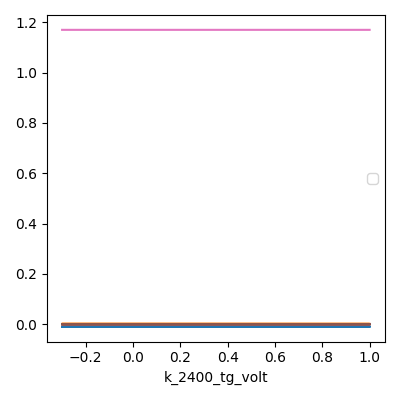

2026-08-24 13:00:51,064 [INFO] Completed in 0h 32m 28s


2026-08-24 13:00:51,065 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260824-vti-02\data\3\data.tsv.gz



run id = 3   C:\Users\DGG\VTI_local_data\zack\20260824-vti-02\data\3\data.tsv.gz
post: V_bg = +0.4000 V   V_tg = +1.0000 V   T_sample = 1.170 K   B = +0.0063 T


In [21]:
# HERA — plan step P2 (re-run after run 2 died at point 3 in the plotter subprocess).
# Identical measurement to run 2; the ONLY change is that the 2D live plot is gone.
# coarse (n, D) gate map, B = 0, base T.
# The primary stacking discriminator: R at the CNP as a function of displacement field.
# ---------------------------------------------------------------- preconditions
assert_thermometry_live("T_sample", VTI.temp_logfile_candidates["T_sample"],
                        max_age=15, max_period=12)
_Ts = T_sample()
_B = magnet.field()
_Vsi = dc205.voltage()
_Vtg, _Vbg = k_tg.volt(), k_bg.volt()
_out_tg, _out_bg = k_2400_tg.output(), k_2400_bg.output()
print(f"pre: T_sample = {_Ts:.3f} K          (expect 1.10-1.40)")
print(f"pre: B        = {_B:+.4f} T         (expect |B| <= 0.02; this cell does not move the magnet)")
print(f"pre: V_si     = {_Vsi:+.4f} V        (expect 0; this cell does not move Si)")
print(f"pre: V_tg     = {_Vtg:+.4f} V        (expect 0.000)")
print(f"pre: V_bg     = {_Vbg:+.4f} V        (expect -1.300, where run 1 ended = this map's first row)")
print(f"pre: outputs  = TG {_out_tg} / BG {_out_bg}")
print(f"pre: sr0 tau={sr0.time_constant():g}s sens={sr0.sensitivity():.3g}V | "
      f"sr1 tau={sr1.time_constant():g}s sens={sr1.sensitivity():.3g}V")
assert 1.10 <= _Ts <= 1.40, f"T_sample {_Ts} K outside base window"
assert abs(_B) <= 0.02, f"B = {_B} T, expected ~0"
assert abs(_Vsi) <= 1e-3, f"V_si = {_Vsi} V, expected 0"
assert bool(_out_tg) and bool(_out_bg), "Keithley source output OFF — gate sets would be inert"
# the dwell below is 7*tau; if tau drifted back up, the dwell would silently be non-compliant
assert sr0.time_constant() == 0.1 and sr1.time_constant() == 0.1, "tau is not 0.1 s — dwell would be wrong"
assert sr1.sensitivity() == 1e-3, "sr1 sensitivity is not 1 mV — Rxx range would be wrong"

# ------------------------------------------------------------------ the map
DATA_DIR = os.path.join(main_dir, "data")
VTG = spoints(-0.30, 1.00, 66)    # fast, 20 mV steps  (small span -> cheap flyback)
VBG = spoints(-1.30, 0.40, 35)    # slow, 50 mV steps  (starts where run 1 ended)
FAST_DELAY = 0.7                  # 7*tau at tau = 0.1 s — compliant
SLOW_DELAY = 0.7

# sanity: every point of this grid must sit inside the committed validators
assert VTG.min() >= -0.3 and VTG.max() <= 1.0, "fast axis outside the TG operating limit"
assert VBG.min() >= -1.3 and VBG.max() <= 2.0, "slow axis outside the BG operating limit"

meas_config["comments"] = ("gate-map — coarse (n, D) map at B = 0, base T; the CNP line runs "
                           "diagonally across this window and R_CNP(D) is the primary "
                           "ABAB / ABCA / ABCB discriminator")
meas_config["sample_temperature:"] = _Ts
meas_config["Si (V)"] = _Vsi

s = sweep.AsyncStation(meas_config, basedir=DATA_DIR)
s.fp(sr0.X).fp(sr0.Y).fp(sr1.X).fp(sr1.Y)
s.fp(k_2400_tg.curr).fp(k_2400_bg.curr).fp(T_sample)
s.add_comment("gate-map")
s.add_comment(
    "2D megasweep | slow V_bg -1.300 -> +0.400 V, 35 rows @ 50 mV | "
    "fast V_tg -0.300 -> +1.000 V, 66 pts @ 20 mV | 2310 pts | "
    "V_si = 0.000 V | B = 0 T | T = base (~1.17 K) | "
    "fast_delay 0.7 s = 7*tau (tau 0.1 s, 24 dB/oct), slow_delay 0.7 s | "
    "I_bias 10.0 nA (1.0 V / 100 MOhm @ 13.777 Hz) | "
    "sr0 = drain current T_0 -> B_3, Ithaco -1e6, sens 20 mV | "
    "sr1 = Vxx B_1-B_2, sens 1 mV | "
    "window chosen so the CNP line is inside it: from run 1 the CNP sits at "
    "V_bg = -0.250 V when V_tg = 0, so the line is V_bg = -1.158*V_tg - 0.250 and it "
    "leaves the TG box at V_bg = +0.097 — rows above ~+0.1 V never cross the CNP, "
    "which is why the slow axis stops at +0.400 instead of +2.000 (that upper half "
    "is pure electron doping and would have cost ~25 min for no stacking information) | "
    "re-run of run 2, which died at point 3 with BrokenPipeError from the 2D live-plot "
    "subprocess; no measurement parameter changed"
)
s.plot(k_tg.volt, [sr0.X, sr0.Y, sr1.X, sr1.Y,
                   k_2400_tg.curr, k_2400_bg.curr, T_sample])
# NO 2D live plot: sweep.plot rebuilds the whole mesh (ax.clear + griddata + pcolormesh)
# on EVERY point — O(N^2) in the plotter subprocess, and degenerate while the slow axis
# still has a single unique value. That is what killed run 2 at point 3 (BrokenPipeError
# from Plotter.add_point). The rig card already says plot.png is not the map — re-form
# from the TSV. The 1D channel plots below are the configuration that survived runs 0 and 1.

res = s.megasweep(k_bg.volt, VBG, k_tg.volt, VTG,
                  slow_delay=SLOW_DELAY, fast_delay=FAST_DELAY, init_delay=True)
print(f"\nrun id = {res.id}   {res.datapath}")
print(f"post: V_bg = {k_bg.volt():+.4f} V   V_tg = {k_tg.volt():+.4f} V   "
      f"T_sample = {T_sample():.3f} K   B = {magnet.field():+.4f} T")


## HERA — P4: Landau fan at D = 0 — independent test of the band structure

> **13:08** · landau-fan: 2D multimegasweep, slow magnet.field 0.75 to 6.0 T x40 uniform in 1/B, fast co-swept (V\_tg,V\_bg) along measured D=0 line (V\_bg=1.2737\*V\_tg), V\_tg -0.30 to +0.60 V x46 @ 20 mV, n=-1.04 to +2.10e12 cm-2, 1840 pts, T=base, delay 0.7/1.0 s · **ETA ~14:38** (≈1h30m)

Plan step **P4**. The gate map has taken the call a long way: R at neutrality rises
**10.4×** with displacement field (296 Ω → 3074 Ω), and its minimum sits at
**D/ε₀ = 0.000 ± 0.008 V/nm** with the two branches symmetric to within 7 % out to
|D| = 0.08 V/nm. That excludes ABAB (a band-overlapped semimetal would not gap like that)
and disfavours ABCB (which, lacking inversion symmetry, must put its minimum at finite D).
The remaining hypothesis is **ABCA**.

Everything above, though, is one measurement of one quantity. This fan is an
**independent** test, of the band structure rather than the gap:

- **Landau-level degeneracy.** A rhombohedral N-layer stack carries an N-fold
  orbitally-degenerate zero-energy level; for tetralayer ABCA that is 4 × 4 (spin×valley)
  = 16 states, so the first flanking gaps fall at ν = ±8. A Bernal tetralayer decomposes
  into two bilayer-like sets whose levels arrive at different fields, giving a visibly
  different sequence. Counting filling factors settles it on band structure alone.
- **Fermi-pocket count.** One SdH tone carrying the full Onsager frequency ⇒ a single
  quartic band (ABCA); two tones splitting it ⇒ two pockets (ABAB/ABCB).
- **The first absolute density calibration.** Every number so far rests on the
  *geometry prior* for c_tg. LL slopes give dn/dB = νe/h directly, which either confirms
  that prior or corrects it. Note the map already moved the *ratio*: measured
  c_tg/c_bg = **1.2737 ± 0.0470** against the prior's 1.1579, and this cell uses the
  measured value to define the D = 0 line, not the prior.

**Design.** Fast axis is density along the measured D = 0 line (V_bg = 1.2737·V_tg),
n = −1.04 → +2.10 × 10¹² cm⁻² with the CNP at V_tg = −0.003, so the fan is centred on
neutrality and covers both carrier signs. Slow axis is field on a **1/B-uniform grid**
(`field_invB`), which is what `sdh_fft` wants — no resampling, and it naturally puts more
rows at low field where the levels converge. D = 0 is chosen deliberately: it is the
symmetric point, so the band structure is seen unperturbed.

`magnet.field` is **followed per point** because the rig card is explicit that this
supply's setpoint is not readable as field — only the measured current is truth.

**Cost** ~1 h 15 m: 5 min to reach 0.75 T, ~38 min of ramping spread across the 40 rows
(the magnet's fixed 0.137 T/min is the floor and dominates), ~28 min of measurement,
~2 min of flyback. Priced at 1 h 30 m. Field is the expensive, one-way axis, so this runs
**upward once** and does not re-traverse — the session's remaining field need after this
is the ramp back to zero.

**Checkpoints:** first row read for clipping and leakage (the gates sit at new values
here); then per-row digests, with the decision at row ~10 (B ≈ 1.2 T) — if no oscillatory
structure is developing by ~2 T I will reconsider whether the mobility supports a fan at
all rather than spend the full hour. Ceiling is 6 T, not the 10 T session cap, precisely
because the ramp is the cost: 6 T already puts ν = ±8 comfortably inside the density
window, and every extra tesla is ~7 min each way.


T_sample: VTI_sample.txt live — age 5s, period 5s
pre: T_sample = 1.170 K     (expect 1.10-1.40)
pre: B        = +0.0063 T    (measured readback; this cell ramps the magnet)
pre: psw=True output=True  (field() raises if either is off)
pre: V_si     = +0.0000 V   (expect 0; this cell does not move Si)
pre: outputs  = TG True / BG True
pre: sr0 tau=0.1s sens=0.02V | sr1 tau=0.1s sens=0.001V
2026-08-24 13:08:06,420 [INFO] Starting multimegasweep with ID 4


2026-08-24 13:08:06,421 [INFO] Minimum duration 0h 22m 8s


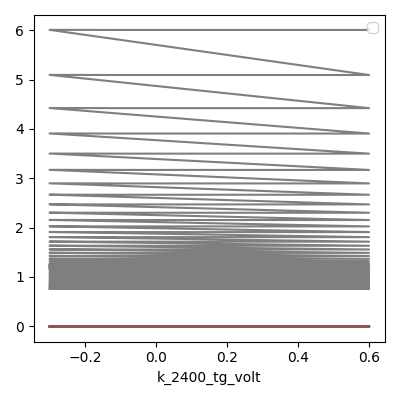

2026-08-24 14:21:55,005 [INFO] Completed in 1h 13m 47s


2026-08-24 14:21:55,005 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260824-vti-02\data\4\data.tsv.gz



run id = 4   C:\Users\DGG\VTI_local_data\zack\20260824-vti-02\data\4\data.tsv.gz
post: B = +6.0063 T   V_tg = +0.6000 V   V_bg = +0.7640 V   T_sample = 1.258 K


In [22]:
# HERA — plan step P4: Landau fan at fixed D = 0, base T.
# Density (co-swept V_tg, V_bg along the measured D = 0 line) is the fast axis;
# field is the slow axis on a 1/B-uniform grid so sdh_fft needs no resample.
# ---------------------------------------------------------------- preconditions
assert_thermometry_live("T_sample", VTI.temp_logfile_candidates["T_sample"],
                        max_age=15, max_period=12)
_Ts = T_sample()
_B = magnet.field()
_Vsi = dc205.voltage()
_psw, _outp = magnet.persistent_switch_on(), magnet.output_enabled()
_out_tg, _out_bg = k_2400_tg.output(), k_2400_bg.output()
print(f"pre: T_sample = {_Ts:.3f} K     (expect 1.10-1.40)")
print(f"pre: B        = {_B:+.4f} T    (measured readback; this cell ramps the magnet)")
print(f"pre: psw={_psw} output={_outp}  (field() raises if either is off)")
print(f"pre: V_si     = {_Vsi:+.4f} V   (expect 0; this cell does not move Si)")
print(f"pre: outputs  = TG {_out_tg} / BG {_out_bg}")
print(f"pre: sr0 tau={sr0.time_constant():g}s sens={sr0.sensitivity():.3g}V | "
      f"sr1 tau={sr1.time_constant():g}s sens={sr1.sensitivity():.3g}V")
assert 1.10 <= _Ts <= 1.40, f"T_sample {_Ts} K outside base window"
assert abs(_B) <= 0.05, f"B = {_B} T, expected ~0 at the start of the fan"
assert bool(_psw) and bool(_outp), "persistent switch or output off — magnet cannot ramp"
assert abs(_Vsi) <= 1e-3, f"V_si = {_Vsi} V, expected 0"
assert bool(_out_tg) and bool(_out_bg), "Keithley source output OFF — gate sets would be inert"
assert sr0.time_constant() == 0.1 and sr1.time_constant() == 0.1, "tau is not 0.1 s"
assert sr1.sensitivity() == 1e-3, "sr1 sensitivity is not 1 mV"

# --------------------------------------- the D = 0 line, from THIS session's map
# run 3 CNP-line fit (a4_symmetry): V_tg = -0.7851*V_bg - 0.0060
#   => measured c_tg/c_bg = 1.2737 +/- 0.0470   (geometry prior was 1.1579)
# D = 0  <=>  c_tg*V_tg = c_bg*V_bg  <=>  V_bg = 1.2737 * V_tg
RATIO = 1.2737                      # measured this session, NOT the geometry prior
VTG = spoints(-0.30, 0.60, 46)      # 20 mV steps along the D = 0 line
VBG = RATIO * VTG                   # co-swept partner
# n = 2*c_tg*(V_tg + 0.003)/e  along this line  ->  -1.04e12 .. +2.10e12 cm^-2
assert VTG.min() >= -0.3 and VTG.max() <= 1.0, "fast V_tg outside the TG operating limit"
assert VBG.min() >= -1.3 and VBG.max() <= 2.0, "fast V_bg outside the BG operating limit"

BVEC = field_invB(0.75, 6.0, 40)    # uniform in 1/B, ascending
assert BVEC.max() <= 10.0, "field vector exceeds the session cap"

DATA_DIR = os.path.join(main_dir, "data")
meas_config["comments"] = ("landau-fan — Rxx(n, B) at fixed D = 0 on the session-measured "
                           "CNP line; LL degeneracy + SdH tone count + the first ABSOLUTE "
                           "density calibration (everything so far rests on the geometry prior)")
meas_config["sample_temperature:"] = _Ts
meas_config["Si (V)"] = _Vsi

s = sweep.AsyncStation(meas_config, basedir=DATA_DIR)
s.fp(sr0.X).fp(sr0.Y).fp(sr1.X).fp(sr1.Y)
s.fp(k_2400_tg.curr).fp(k_2400_bg.curr).fp(T_sample).fp(magnet.field)
s.add_comment("landau-fan")
s.add_comment(
    "2D multimegasweep | slow magnet.field 0.750 -> 6.000 T, 40 rows UNIFORM IN 1/B "
    "(hera.analysis.field_invB, so sdh_fft needs no resample) | "
    "fast co-swept (V_tg, V_bg) along D = 0: V_tg -0.300 -> +0.600 V, 46 pts @ 20 mV, "
    "V_bg = 1.2737*V_tg | n = -1.04e12 .. +2.10e12 cm^-2, CNP at V_tg = -0.003 | "
    "1840 pts | V_si = 0.000 V | T = base (~1.17 K) | "
    "fast_delay 0.7 s = 7*tau (tau 0.1 s, 24 dB/oct), slow_delay 1.0 s after each field ramp | "
    "I_bias 10.0 nA | sr0 = drain current T_0 -> B_3, Ithaco -1e6, sens 20 mV | "
    "sr1 = Vxx B_1-B_2, sens 1 mV | magnet.field followed per point (the setpoint is NOT "
    "the field on this supply) | ratio 1.2737 is the c_tg/c_bg MEASURED from run 3's CNP "
    "line, not the geometry prior 1.1579"
)
s.plot(k_tg.volt, [sr0.X, sr0.Y, sr1.X, sr1.Y,
                   k_2400_tg.curr, k_2400_bg.curr, T_sample, magnet.field])
# no 2D live plot — it killed run 2 (see the P2 re-run cell)

res = s.multimegasweep([magnet.field], [BVEC], [k_tg.volt, k_bg.volt], [VTG, VBG],
                       slow_delay=1.0, fast_delay=0.7, init_delay=True)
print(f"\nrun id = {res.id}   {res.datapath}")
print(f"post: B = {magnet.field():+.4f} T   V_tg = {k_tg.volt():+.4f} V   "
      f"V_bg = {k_bg.volt():+.4f} V   T_sample = {T_sample():.3f} K")


## HERA — P4b: SdH trace measured through the ramp down

> **14:22** · sdh-downsweep: 2D multimegasweep, slow magnet.field 6.0 to 0.5 T x100 DESCENDING uniform in 1/B, fast 5 fixed densities on D=0 line (n = -0.8/0.5/1.0/1.5/2.0 e12 cm-2), 500 pts, T=base; FFT res 0.55 T, Nyquist 27.3 T · **ETA ~15:22** (≈1h)

Plan step **P4b**. The activation ladder (P5) must be run at zero field, so the 6 T → 0
ramp is unavoidable — 40 minutes of the magnet's fixed 0.137 T/min. Measuring through it
costs about **13 minutes extra** and turns dead time into the session's highest-resolution
SdH dataset. That is the whole justification for this cell.

**Why the fan alone is not enough for the pocket count.** Run 4's 1/B record (0.75 → 6 T,
40 rows) gives an FFT resolution of 0.86 T but a Nyquist frequency of only ~17 T, while the
Onsager frequency at the top of its density window (n = 2.09 × 10¹² cm⁻²) is 21.6 T — those
columns **alias**, and an aliased tone is worse than no tone. This sweep uses 100 field
points over a longer 1/B baseline (0.5 → 6 T): resolution **0.55 T**, Nyquist **27.3 T**,
comfortably above every Onsager frequency in play. The fan is the right instrument for the
Landau-level *sequence*; this is the right one for *counting tones*.

**Design.** Five fixed densities on the session-measured D = 0 line
(n = −0.80, +0.50, +1.00, +1.50, +2.00 × 10¹² cm⁻²), verified to sit at D/ε₀ = 0.000
exactly and inside the committed gate box. Field descends on a `field_invB` grid so
`sdh_fft` needs no resampling. One tone carrying the full Onsager value means a single
Fermi pocket (ABCA); two tones splitting it means two pockets (ABAB/ABCB). Because the
five densities span a 4× range, the tones must also **scale linearly with n** — that is a
much stronger check than any single column, and it is what would expose a spurious peak.

`magnet.field` is followed per point, which run 4 proved is not optional: the measured
field sits **+6.5 mT above the setpoint** with ~2 mT of within-row spread, ~0.9 % at
0.75 T, and that would propagate directly into the extracted frequencies.

**Sensitivity is deliberately left at 1 mV.** These are finite-density columns where Rxx
stays modest; the n = +0.50 column sits at ν ≈ 3.4 at 6 T and may clip near its
peaks, which the analysis masks. Coarsening the range to protect it would destroy the
SdH *minima* — run 4 showed those reaching 0–6 Ω, and the minima are half the signal.

**Ends at 0.5 T**, not 0: a short bare ramp then takes the magnet to zero for the ladder,
which is cheaper than measuring the last half-tesla where there is no SdH left to see.

**Checkpoints:** first rows for clipping and for the current sag (at 6 T the drain current
was already down to 6.4 nA at neutrality — these columns are away from it and should sit
near 9.9 nA); then per-row digests. Priced at 1 h.


T_sample: VTI_sample.txt live — age 2s, period 5s
pre: T_sample = 1.258 K     (expect base, 1.10-1.40)
pre: B        = +6.0064 T    (measured; expect ~6 T where the fan ended)
pre: psw=True output=True
pre: V_si     = +0.0000 V
pre: sr1 tau=0.1s sens=0.001V
2026-08-24 14:22:49,947 [INFO] Starting multimegasweep with ID 5


2026-08-24 14:22:49,948 [INFO] Minimum duration 0h 6m 40s


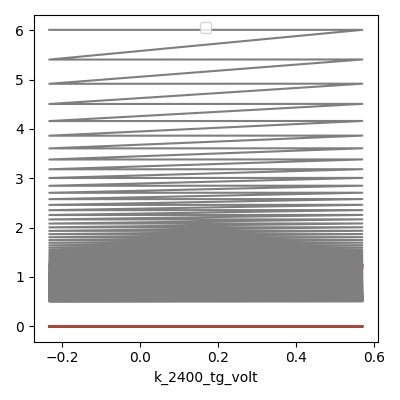

2026-08-24 15:23:01,545 [INFO] Completed in 1h 0m 11s


2026-08-24 15:23:01,546 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260824-vti-02\data\5\data.tsv.gz



run id = 5   C:\Users\DGG\VTI_local_data\zack\20260824-vti-02\data\5\data.tsv.gz
post: B = +0.5060 T   T_sample = 1.180 K


In [23]:
# HERA — P4b: SdH trace on the way DOWN. The activation ladder needs B = 0, so the
# 6 T -> 0 ramp is unavoidable; measuring through it costs ~13 min over a bare ramp and
# yields the session's finest-resolution SdH data (100 field points uniform in 1/B at 5
# fixed densities) for the Fermi-pocket count.
# ---------------------------------------------------------------- preconditions
assert_thermometry_live("T_sample", VTI.temp_logfile_candidates["T_sample"],
                        max_age=15, max_period=12)
_Ts = T_sample()
_B = magnet.field()
_Vsi = dc205.voltage()
_psw, _outp = magnet.persistent_switch_on(), magnet.output_enabled()
print(f"pre: T_sample = {_Ts:.3f} K     (expect base, 1.10-1.40)")
print(f"pre: B        = {_B:+.4f} T    (measured; expect ~6 T where the fan ended)")
print(f"pre: psw={_psw} output={_outp}")
print(f"pre: V_si     = {_Vsi:+.4f} V")
print(f"pre: sr1 tau={sr1.time_constant():g}s sens={sr1.sensitivity():.3g}V")
assert 1.10 <= _Ts <= 1.40, f"T_sample {_Ts} K outside base window"
assert 5.5 <= _B <= 6.5, f"B = {_B} T — expected the fan to have left the magnet near 6 T"
assert bool(_psw) and bool(_outp), "persistent switch or output off — magnet cannot ramp"
assert abs(_Vsi) <= 1e-3, f"V_si = {_Vsi} V, expected 0"
assert sr0.time_constant() == 0.1 and sr1.time_constant() == 0.1, "tau is not 0.1 s"
assert sr1.sensitivity() == 1e-3, "sr1 sensitivity is not 1 mV"

# ---- fixed densities on the measured D = 0 line -----------------------------
# n [e12 cm^-2] = 3.49*(V_tg + 0.003) along V_bg = 1.2737*V_tg
RATIO = 1.2737
N_TARGETS = np.array([-0.80, 0.50, 1.00, 1.50, 2.00])   # e12 cm^-2
VTG_N = N_TARGETS / 3.49 - 0.003
VBG_N = RATIO * VTG_N
assert VTG_N.min() >= -0.3 and VTG_N.max() <= 1.0, "V_tg outside the operating limit"
assert VBG_N.min() >= -1.3 and VBG_N.max() <= 2.0, "V_bg outside the operating limit"

BVEC = field_invB(6.0, 0.5, 100)     # DESCENDING, uniform in 1/B -> sdh_fft needs no resample
assert BVEC.max() <= 10.0, "field vector exceeds the session cap"
# FFT: d(1/B) = 1.833 /T -> resolution 0.55 T; Nyquist 27 T vs max Onsager 20.7 T at n=2e12

DATA_DIR = os.path.join(main_dir, "data")
meas_config["comments"] = ("sdh-downsweep — Rxx(B) at 5 fixed densities on the D = 0 line, "
                           "6 -> 0.5 T uniform in 1/B; Fermi-pocket count from the SdH tone "
                           "structure, measured through the ramp the T-ladder requires anyway")
meas_config["sample_temperature:"] = _Ts
meas_config["Si (V)"] = _Vsi

s = sweep.AsyncStation(meas_config, basedir=DATA_DIR)
s.fp(sr0.X).fp(sr0.Y).fp(sr1.X).fp(sr1.Y)
s.fp(k_2400_tg.curr).fp(k_2400_bg.curr).fp(T_sample).fp(magnet.field)
s.add_comment("sdh-downsweep")
s.add_comment(
    "2D multimegasweep | slow magnet.field 6.000 -> 0.500 T DESCENDING, 100 rows uniform "
    "in 1/B (field_invB) | fast co-swept (V_tg, V_bg) at 5 fixed densities on the measured "
    f"D = 0 line: n = {list(N_TARGETS)} e12 cm^-2, V_tg = {list(np.round(VTG_N, 4))}, "
    f"V_bg = 1.2737*V_tg | 500 pts | T = base | V_si = 0.000 V | "
    "fast_delay 0.7 s = 7*tau, slow_delay 0.5 s (the magnet's own settle_s=3 already "
    "gates each field setpoint) | I_bias 10.0 nA | sr1 sens 1 mV | "
    "magnet.field followed per point (setpoint is NOT field on this supply) | "
    "d(1/B) = 1.833 /T -> FFT resolution 0.55 T, Nyquist 27 T vs 20.7 T Onsager at n=2e12 | "
    "ends at 0.5 T; a short bare ramp then takes the magnet to 0 for the T-ladder"
)
s.plot(k_tg.volt, [sr0.X, sr0.Y, sr1.X, sr1.Y,
                   k_2400_tg.curr, k_2400_bg.curr, T_sample, magnet.field])

res = s.multimegasweep([magnet.field], [BVEC], [k_tg.volt, k_bg.volt], [VTG_N, VBG_N],
                       slow_delay=0.5, fast_delay=0.7, init_delay=True)
print(f"\nrun id = {res.id}   {res.datapath}")
print(f"post: B = {magnet.field():+.4f} T   T_sample = {T_sample():.3f} K")


## HERA — P5: temperature ladder — the activation gap Δ(D)

> **15:23** · tladder-cnp: ramp B 0.5 to 0 T, then 7 temperatures (base, 8, 12, 17, 23, 30, 40 K via set\_both ratio 0.95); at each, 245-pt co-swept multisweep along the measured CNP line x5 perpendicular V\_bg offsets, D/eps0 -0.094 to +0.285 V/nm; one run dir per temperature · **ETA ~16:13** (≈50 min)

Plan step **P5**, and the last measurement of the session. Everything so far says the gap
is real and centred at D = 0, but says it in *resistance*. This says it in **meV**.

**Why this is the measurement that closes the argument.** Run 3's R_CNP(D) has one feature
that does not look like a cleanly growing single-particle gap: above D/ε₀ ≈ 0.23 V/nm it
**saturates** near 3 kΩ instead of continuing up exponentially. That is the signature of a
parallel conduction path or disorder-induced in-gap states putting a floor under the
resistance — and if that floor dominates, "R rose 10×" would be a weaker claim than it
looks. Thermal activation settles it: fitting R_CNP(T) ∝ exp(Δ/2k_BT) at each D returns a
gap in meV whose *D-dependence* is the physics. ABCA requires Δ(D) growing with |D| and
extrapolating to ≈ 0 at D = 0; ABCB requires a finite Δ at D = 0.

**It is also the one measurement immune to the unknown geometry.** The device card gives no
Hall-bar dimensions, so every resistance this session is in ohms, not ohms-per-square, and
the geometric prefactor is unknown. Activation is a *ratio* measurement — the prefactor
cancels exactly. So does the ~7–10 % probe-loading systematic, provided it does not itself
depend on temperature.

**Design.** At each temperature, one 245-point co-swept `multisweep` that walks the
session-measured CNP line (`V_bg = −1.2737·V_tg − 0.00764`) five times at perpendicular
V_bg offsets of 0, ±0.05, ±0.10 V, folded into a single path and reshaped to (5, 49) in
analysis. The offsets matter: they let R_CNP be taken as the **maximum over offsets** at
each point along the line, so a few-mV drift in the fitted line — or thermal drift of the
CNP itself as the sample warms — cannot masquerade as a change in gap. One sweep covers
D/ε₀ = −0.094 → +0.285 V/nm, so every temperature yields a complete R_CNP(D) curve in
under 4 minutes.

**Temperatures:** base, then 8, 12, 17, 23, 30, 40 K via `set_both(T, ratio=0.95)` — the
rig-card-sanctioned ratio; any deviation is consent-gated and is not used. Points are
accepted on **stability, not proximity**: the rig card records that the sample loop is
untuned, overshoots ~+1.4 K, and recovers only as fast as the bath allows, so waiting for
|T − setpoint| to close never converges below ~20 K. `T_sample` is followed per point, so
the Arrhenius fit uses the temperature actually measured, never the setpoint. The ladder
starts at 8 K deliberately — the rig's electron temperature is ~8 K, so nothing below that
carries independent information.

**Field to zero first.** Activation must be measured at B = 0 or a Landau gap contaminates
Δ. The down-sweep left the magnet at 0.5 T, so this cell owns the last leg down and
asserts |B| ≤ 0.05 T after the blocking ramp before any heater is touched.

**Ends warm, deliberately.** This is the last measurement, and cooling back to base from
40 K is passive and slow (τ ≈ 27 min). Close-out does not require base temperature — it
requires the field at zero, the gates at zero, and both heater ranges off.

**Cost** ~50 min: ~4 min of ramp to zero, then 7 × (settle ~3–4 min + sweep ~4 min).
**Checkpoints:** the printed settle line at each temperature (T and its σ), and each run id
as it lands — seven separate run directories, so a failure at any temperature costs one
point, not the ladder.


T_sample: VTI_sample.txt live — age 2s, period 5s
pre: T_sample = 1.180 K     (expect base, 1.10-1.40)
pre: B        = +0.5063 T    (expect ~0.5 T, where the down-sweep ended)
pre: V_si     = +0.0000 V
pre: heater ranges sample=0 vaporizer=0
pre: sr0 tau=0.1s | sr1 tau=0.1s sens=0.001V
ramping +0.5063 -> 0.000 T (blocking, ~3.7 min) ...


field now +0.0028 T (measured readback)

=== base temperature (heaters off) ===
    T_sample = 1.176 K   T_vaporizer = 0.954 K
2026-08-24 15:27:35,607 [INFO] Starting multisweep with ID 6


2026-08-24 15:27:35,608 [INFO] Minimum duration 0h 2m 51s


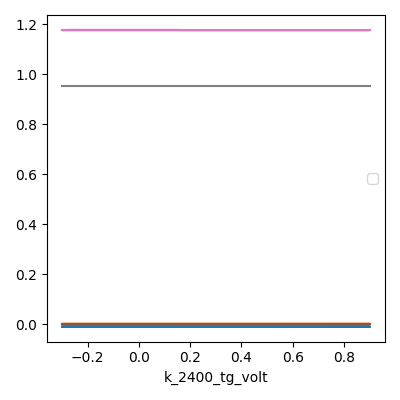

2026-08-24 15:31:20,877 [INFO] Completed in 0h 3m 44s


2026-08-24 15:31:20,877 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260824-vti-02\data\6\data.tsv.gz


    run 6 written

=== set_both(8.0, ratio=0.95) ===


    settled: T = 8.034 K (sigma 0.0309 K over 100 s, target 8.0 K) after 240 s
    T_sample = 8.034 K   T_vaporizer = 7.599 K
2026-08-24 15:35:20,919 [INFO] Starting multisweep with ID 7


2026-08-24 15:35:20,920 [INFO] Minimum duration 0h 2m 51s


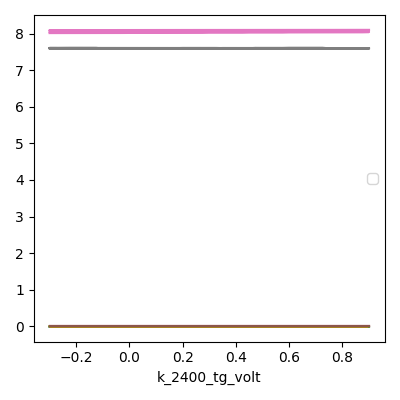

2026-08-24 15:39:07,739 [INFO] Completed in 0h 3m 46s


2026-08-24 15:39:07,740 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260824-vti-02\data\7\data.tsv.gz


    run 7 written

=== set_both(12.0, ratio=0.95) ===


    settled: T = 12.042 K (sigma 0.0354 K over 100 s, target 12.0 K) after 100 s
    T_sample = 12.042 K   T_vaporizer = 11.400 K
2026-08-24 15:40:47,780 [INFO] Starting multisweep with ID 8


2026-08-24 15:40:47,780 [INFO] Minimum duration 0h 2m 51s


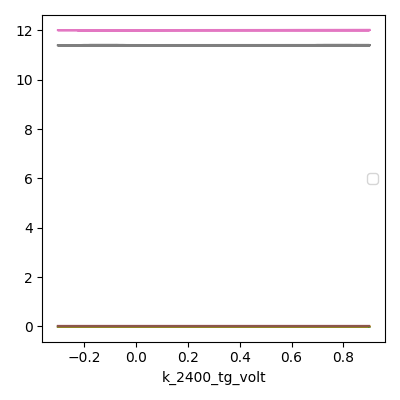

2026-08-24 15:44:35,114 [INFO] Completed in 0h 3m 46s


2026-08-24 15:44:35,115 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260824-vti-02\data\8\data.tsv.gz


    run 8 written

=== set_both(17.0, ratio=0.95) ===


    settled: T = 17.030 K (sigma 0.0212 K over 100 s, target 17.0 K) after 120 s
    T_sample = 17.030 K   T_vaporizer = 16.149 K
2026-08-24 15:46:35,152 [INFO] Starting multisweep with ID 9


2026-08-24 15:46:35,153 [INFO] Minimum duration 0h 2m 51s


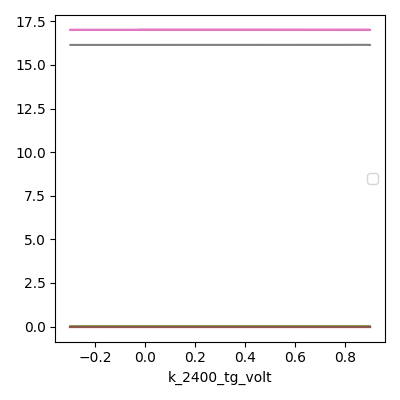

2026-08-24 15:50:22,016 [INFO] Completed in 0h 3m 46s


2026-08-24 15:50:22,016 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260824-vti-02\data\9\data.tsv.gz


    run 9 written

=== set_both(23.0, ratio=0.95) ===


    settled: T = 23.011 K (sigma 0.0079 K over 100 s, target 23.0 K) after 120 s
    T_sample = 23.011 K   T_vaporizer = 21.851 K
2026-08-24 15:52:22,076 [INFO] Starting multisweep with ID 10


2026-08-24 15:52:22,078 [INFO] Minimum duration 0h 2m 51s


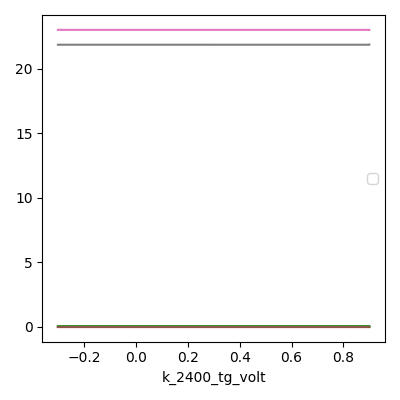

2026-08-24 15:56:09,123 [INFO] Completed in 0h 3m 46s


2026-08-24 15:56:09,124 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260824-vti-02\data\10\data.tsv.gz


    run 10 written

=== set_both(30.0, ratio=0.95) ===


    settled: T = 30.012 K (sigma 0.0101 K over 100 s, target 30.0 K) after 120 s
    T_sample = 30.012 K   T_vaporizer = 28.500 K
2026-08-24 15:58:09,144 [INFO] Starting multisweep with ID 11


2026-08-24 15:58:09,144 [INFO] Minimum duration 0h 2m 51s


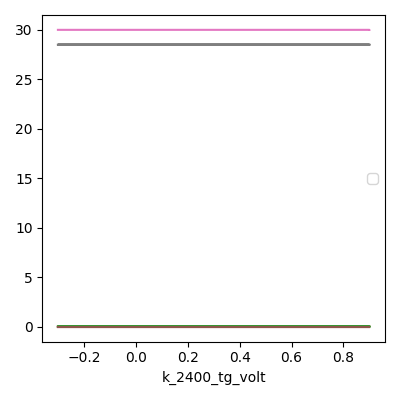

2026-08-24 16:01:55,719 [INFO] Completed in 0h 3m 46s


2026-08-24 16:01:55,719 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260824-vti-02\data\11\data.tsv.gz


    run 11 written

=== set_both(40.0, ratio=0.95) ===


    settled: T = 40.008 K (sigma 0.0024 K over 100 s, target 40.0 K) after 140 s
    T_sample = 40.008 K   T_vaporizer = 38.001 K
2026-08-24 16:04:15,744 [INFO] Starting multisweep with ID 12


2026-08-24 16:04:15,745 [INFO] Minimum duration 0h 2m 51s


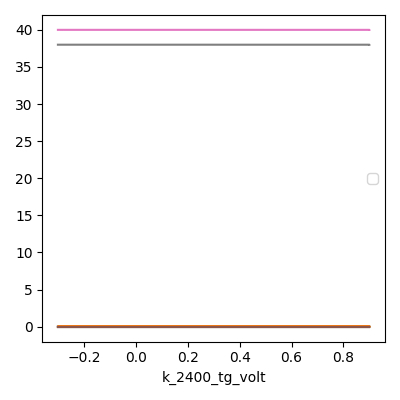

2026-08-24 16:08:03,011 [INFO] Completed in 0h 3m 46s


2026-08-24 16:08:03,012 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260824-vti-02\data\12\data.tsv.gz


    run 12 written

=== ladder complete ===
  setpoint   None K -> T_sample  1.176 K -> run 6
  setpoint    8.0 K -> T_sample  8.034 K -> run 7
  setpoint   12.0 K -> T_sample 12.042 K -> run 8
  setpoint   17.0 K -> T_sample 17.030 K -> run 9
  setpoint   23.0 K -> T_sample 23.011 K -> run 10
  setpoint   30.0 K -> T_sample 30.012 K -> run 11
  setpoint   40.0 K -> T_sample 40.008 K -> run 12
post: T_sample = 40.001 K  T_vaporizer = 38.000 K  B = +0.0063 T  V_tg = +0.9000  V_bg = -1.0540


In [24]:
# HERA — plan step P5: temperature ladder at B = 0. Activation gap Delta(D) at the CNP.
# One CNP-line patch per temperature; each temperature writes its own run dir.
# ---------------------------------------------------------------- preconditions
assert_thermometry_live("T_sample", VTI.temp_logfile_candidates["T_sample"],
                        max_age=15, max_period=12)
_Ts = T_sample()
_B = magnet.field()
_Vsi = dc205.voltage()
print(f"pre: T_sample = {_Ts:.3f} K     (expect base, 1.10-1.40)")
print(f"pre: B        = {_B:+.4f} T    (expect ~0.5 T, where the down-sweep ended)")
print(f"pre: V_si     = {_Vsi:+.4f} V")
print(f"pre: heater ranges sample={heater.sample_range()} vaporizer={heater.vaporizer_range()}")
print(f"pre: sr0 tau={sr0.time_constant():g}s | sr1 tau={sr1.time_constant():g}s "
      f"sens={sr1.sensitivity():.3g}V")
assert 1.10 <= _Ts <= 1.40, f"T_sample {_Ts} K — ladder must start from base"
assert _B <= 1.0, f"B = {_B} T — expected the down-sweep to have left the magnet near 0.5 T"
assert abs(_Vsi) <= 1e-3, f"V_si = {_Vsi} V, expected 0"
assert bool(k_2400_tg.output()) and bool(k_2400_bg.output()), "Keithley output OFF"
assert sr0.time_constant() == 0.1 and sr1.time_constant() == 0.1, "tau is not 0.1 s"
assert sr1.sensitivity() == 1e-3, "sr1 sensitivity is not 1 mV"

# ---------------------------------------- field to zero FIRST
# Activation must be measured at B = 0: a Landau gap at finite field would contaminate
# Delta. The down-sweep ended at 0.5 T, so this cell owns the last leg to zero.
# magnet.field() BLOCKS through the ramp (~4 min at the fixed 0.137 T/min).
if abs(_B) > 0.02:
    print(f"ramping {_B:+.4f} -> 0.000 T (blocking, ~{abs(_B)/0.137:.1f} min) ...")
    magnet.field(0.0)
_B0 = magnet.field()
print(f"field now {_B0:+.4f} T (measured readback)")
assert abs(_B0) <= 0.05, f"B = {_B0} T after ramp — activation needs zero field"

# ---------------------------------------- the CNP-line patch (measured, run 3)
# CNP line: V_tg = -0.7851*V_bg - 0.0060  =>  V_bg = -1.2737*V_tg - 0.00764
# One co-swept 1D path that walks the line five times, each at a different
# perpendicular offset on V_bg, concatenated into a single multisweep. (V_bg cannot
# be both a megasweep slow axis and half of the co-swept fast axis, so the "2D" patch
# is folded into one path and reshaped to (5, 49) in analysis.)
RATIO = 1.2737
VTG_L = spoints(-0.30, 0.90, 49)                  # 25 mV along the line
VBG_L = -RATIO * VTG_L - 0.00764
OFFS = np.array([-0.10, -0.05, 0.0, 0.05, 0.10])  # perpendicular offsets on V_bg
VTG_ALL = np.tile(VTG_L, len(OFFS))
VBG_ALL = np.concatenate([VBG_L + d for d in OFFS])
assert len(VTG_ALL) == len(VBG_ALL) == len(OFFS) * len(VTG_L)
assert VTG_ALL.min() >= -0.3 and VTG_ALL.max() <= 1.0, "V_tg outside the operating limit"
assert VBG_ALL.min() >= -1.3 and VBG_ALL.max() <= 2.0, "V_bg outside the operating limit"
# D/eps0 along the line ~ 0.3158*V_tg + 0.001  ->  -0.094 .. +0.285 V/nm

T_TARGETS = [None, 8.0, 12.0, 17.0, 23.0, 30.0, 40.0]   # None = base, heaters off
assert max(t for t in T_TARGETS if t) <= 100.0, "target above the session T cap"

DATA_DIR = os.path.join(main_dir, "data")


def hover(target, max_wait=600, poll=20, window=5, stab=0.05):
    """Rig-card hover acceptance: accept on STABILITY, not proximity. The sample loop is
    untuned (+1.4 K overshoot, bath-limited recovery), so waiting for |T-target| to close
    never converges below ~20 K. Returns the settled reading."""
    hist = []
    t0 = time.time()
    while time.time() - t0 < max_wait:
        interruptible_sleep(poll)
        hist.append(T_sample())
        if len(hist) >= window:
            w = hist[-window:]
            if float(np.std(w)) < stab:
                print(f"    settled: T = {np.mean(w):.3f} K (sigma {np.std(w):.4f} K over "
                      f"{window * poll} s, target {target} K) after {time.time() - t0:.0f} s")
                return float(np.mean(w))
    print(f"    WARNING: no stability within {max_wait} s; last T = {hist[-1]:.3f} K")
    return hist[-1]


results = []
for T_set in T_TARGETS:
    if T_set is None:
        print(f"\n=== base temperature (heaters off) ===")
        T_now = T_sample()
    else:
        print(f"\n=== set_both({T_set}, ratio=0.95) ===")
        heater.set_both(T_set, ratio=0.95)   # ratio 0.95 per rig card; any other value is
                                             # consent-gated and is deliberately not used
        T_now = hover(T_set)
    T_vap = T_vaporizer()
    print(f"    T_sample = {T_now:.3f} K   T_vaporizer = {T_vap:.3f} K")

    meas_config["comments"] = (f"tladder-cnp — CNP-line patch at T_sample ~ {T_now:.2f} K, "
                               f"B = 0; activation gap Delta(D) at charge neutrality")
    meas_config["sample_temperature:"] = T_now
    meas_config["Si (V)"] = dc205.voltage()

    s = sweep.AsyncStation(meas_config, basedir=DATA_DIR)
    s.fp(sr0.X).fp(sr0.Y).fp(sr1.X).fp(sr1.Y)
    s.fp(k_2400_tg.curr).fp(k_2400_bg.curr).fp(T_sample).fp(T_vaporizer)
    s.add_comment("tladder-cnp")
    s.add_comment(
        f"1D multisweep, co-swept (V_tg, V_bg), 245 pts = 5 offsets x 49 along-line pts "
        f"(reshape to (5, 49) in analysis) | line: V_bg = -1.2737*V_tg - 0.00764 "
        f"(MEASURED CNP line from run 3) | V_tg -0.300 -> +0.900 V @ 25 mV | "
        f"perpendicular V_bg offsets {list(np.round(OFFS, 3))} V so the TRUE Rxx peak is "
        f"captured even if the fitted line drifts; R_CNP(D) = max over offsets per V_tg | "
        f"D/eps0 -0.094 .. +0.285 V/nm | "
        f"T_setpoint = {T_set} K (ratio 0.95), T_sample settled = {T_now:.3f} K, "
        f"T_vaporizer = {T_vap:.3f} K | B = 0 T | V_si = 0.000 V | "
        f"delay 0.7 s = 7*tau (tau 0.1 s, 24 dB/oct) | I_bias 10.0 nA | "
        f"sr0 Ithaco -1e6 sens 20 mV | sr1 sens 1 mV"
    )
    s.plot(k_tg.volt, [sr0.X, sr0.Y, sr1.X, sr1.Y,
                       k_2400_tg.curr, k_2400_bg.curr, T_sample, T_vaporizer])

    res = s.multisweep([k_tg.volt, k_bg.volt], [VTG_ALL, VBG_ALL], delay=0.7)
    results.append((T_set, T_now, res.id))
    print(f"    run {res.id} written")

print("\n=== ladder complete ===")
for T_set, T_now, rid in results:
    print(f"  setpoint {str(T_set):>6} K -> T_sample {T_now:6.3f} K -> run {rid}")
print(f"post: T_sample = {T_sample():.3f} K  T_vaporizer = {T_vaporizer():.3f} K  "
      f"B = {magnet.field():+.4f} T  V_tg = {k_tg.volt():+.4f}  V_bg = {k_bg.volt():+.4f}")


## HERA — close-out: return-to-initial

> **16:10** · close-out return-to-initial: heaters off, TG/BG to 0 V at 5 mV/step, field to 0 T, full readback of field/gates/leakage/temperatures · **ETA ~16:20** (≈10 min)

The brief's close-out step. Order matters: **heaters off first**, so the sample begins
cooling from 40 K while the gates and field ramp; then both Keithley gates to 0 V at their
committed 5 mV/step pacing; then the field to zero (it is already at +0.006 T, where the
ladder left it, so this is a no-op guarded by a read). Finally a full readback of field,
gates, leakage, temperatures and heater ranges for the session log.

**Si is not touched.** It sat at 0.000 V all session — the graphite back gate screens it
from the channel, so it was never needed — and the DC205 ramp is consent-gated. The cell
reads it and flags it for the operator rather than ramping it.

**Lock-in settings are deliberately NOT restored to `state0`.** `sr1` sensitivity
(2 µV → 1 mV) and `sr0`/`sr1` τ (0.3 → 0.1 s) were changed with operator authorisation
because the session-start values were wrong for this device — `sr1` was railed at 2 µV
before the first sweep. Restoring them would hand the next session a known-bad
configuration. The readback records what they actually are.


In [25]:
# HERA — close-out: return-to-initial, per the session brief.
# Field to 0, all three gates to 0 V at their committed pacing, both heater ranges off,
# then a readback of field, gates and temperatures for the session log.
print("=== close-out: return-to-initial ===")
print(f"start: B = {magnet.field():+.4f} T | V_tg = {k_tg.volt():+.4f} V | "
      f"V_bg = {k_bg.volt():+.4f} V | V_si = {dc205.voltage():+.4f} V")
print(f"       T_sample = {T_sample():.3f} K | T_vaporizer = {T_vaporizer():.3f} K | "
      f"heater ranges {heater.sample_range()}/{heater.vaporizer_range()}")

# --- heaters off FIRST so the sample starts cooling while everything else ramps ---
heater.off("both")
print(f"heaters off -> ranges {heater.sample_range()}/{heater.vaporizer_range()}")

# --- gates to 0 V, each at its own committed pacing -------------------------------
# Keithleys sub-step at volt.step = 5 mV; the DC205 ramps at ramp_rate = 0.5 V/s.
# Si is already at 0 and its ramp is consent-gated, so it is only set if it has moved.
k_tg.volt(0.0)
k_bg.volt(0.0)
print(f"gates: V_tg = {k_tg.volt():+.4f} V | V_bg = {k_bg.volt():+.4f} V")
_vsi = dc205.voltage()
if abs(_vsi) > 1e-3:
    print(f"Si is at {_vsi:+.4f} V — NOT ramping it here (the DC205 ramp is consent-gated); "
          f"flagging for the operator")
else:
    print(f"Si: {_vsi:+.4f} V — already at zero, untouched all session")

# --- field to zero (blocking; the magnet has no abort, only a new setpoint) --------
_B = magnet.field()
if abs(_B) > 0.02:
    print(f"ramping B {_B:+.4f} -> 0.000 T (blocking, ~{abs(_B)/0.137:.1f} min) ...")
    magnet.field(0.0)

# --- final readback ---------------------------------------------------------------
print("\n=== final state ===")
print(f"B            = {magnet.field():+.5f} T   (measured readback)")
print(f"magnet       : psw={magnet.persistent_switch_on()} output={magnet.output_enabled()}")
print(f"V_tg         = {k_tg.volt():+.5f} V")
print(f"V_bg         = {k_bg.volt():+.5f} V")
print(f"V_si         = {dc205.voltage():+.5f} V")
print(f"gate leakage : TG {k_2400_tg.curr()*1e12:+.1f} pA | BG {k_2400_bg.curr()*1e12:+.1f} pA")
print(f"T_sample     = {T_sample():.3f} K")
print(f"T_vaporizer  = {T_vaporizer():.3f} K")
print(f"heater ranges= {heater.sample_range()} (sample) / {heater.vaporizer_range()} (vaporizer)")
print(f"sr0          : sens {sr0.sensitivity():.3g} V, tau {sr0.time_constant():g} s, "
      f"slope {sr0.filter_slope():g} dB/oct")
print(f"sr1          : sens {sr1.sensitivity():.3g} V, tau {sr1.time_constant():g} s, "
      f"slope {sr1.filter_slope():g} dB/oct")
print(f"drive        : {sr1.amplitude()} V @ {sr1.frequency()} Hz")
print("\nNOTE: sr1 sensitivity (2 uV -> 1 mV) and sr0/sr1 tau (0.3 -> 0.1 s) were changed "
      "this session with operator authorisation; they are NOT restored to state0, since the "
      "session-start values were wrong for this device (sr1 was railed at 2 uV).")
print("close-out complete — the sample is left cooling toward base with all gates and the "
      "field at zero.")


=== close-out: return-to-initial ===
start: B = +0.0063 T | V_tg = +0.9000 V | V_bg = -1.0540 V | V_si = +0.0000 V
       T_sample = 40.001 K | T_vaporizer = 38.000 K | heater ranges 2/2
heaters off -> ranges 0/0


gates: V_tg = +0.0000 V | V_bg = +0.0000 V
Si: +0.0000 V — already at zero, untouched all session

=== final state ===
B            = +0.00634 T   (measured readback)
magnet       : psw=True output=True
V_tg         = +0.00000 V
V_bg         = +0.00000 V
V_si         = +0.00000 V


gate leakage : TG -98.2 pA | BG +34.0 pA
T_sample     = 40.001 K
T_vaporizer  = 38.001 K
heater ranges= 0 (sample) / 0 (vaporizer)
sr0          : sens 0.02 V, tau 0.1 s, slope 24 dB/oct
sr1          : sens 0.001 V, tau 0.1 s, slope 24 dB/oct
drive        : 1.0 V @ 13.777 Hz

NOTE: sr1 sensitivity (2 uV -> 1 mV) and sr0/sr1 tau (0.3 -> 0.1 s) were changed this session with operator authorisation; they are NOT restored to state0, since the session-start values were wrong for this device (sr1 was railed at 2 uV).
close-out complete — the sample is left cooling toward base with all gates and the field at zero.


## ERRATUM — correcting cell idx 41 (the P4 Landau-fan proposal)

This notebook is append-only, so the erroneous claim below stays on the page. This cell is
the marker a reader needs.

**Cell idx 41 (`## HERA — P4: Landau fan at D = 0`) states:** *"a rhombohedral N-layer stack
carries an N-fold orbitally degenerate zero-energy level; for tetralayer ABCA that is 4 × 4
(spin×valley) = 16 states, so the first flanking gaps fall at ν = ±8. A Bernal tetralayer
decomposes into two bilayer-like sets whose levels arrive at different fields, giving a
visibly different sequence. Counting filling factors settles it on band structure alone."*

**That is wrong.** ABAB tetralayer decomposes into two effective bilayers, each carrying a
2-fold orbital zero level × 4 spin/valley = 8 states, and **both sit at exactly E = 0** — so
ABAB also has 16 zero-energy states, identical to ABCA. The zero-Landau-level degeneracy is
4N for N layers **regardless of stacking order**: it counts *layers*, not stacking. Counting
filling factors therefore does **not** settle ABCA vs ABAB.

**What run 4 actually contributes to the stacking call** is the **Fermi-pocket count** — one
SdH tone proportional to n, where two bilayer-like bands would give two — plus a
cross-check on the density scale. Neither depends on the retracted claim, and the run was
worth doing. See the ana notebook (`Run 4 — landau-fan`) and the final call for the corrected
reasoning.

*No measurement, setpoint or datum is affected by this erratum; it corrects reasoning only.*


## HERA — mandated close-out: `close_out(restore=state0)`

> **16:42** · mandated close\_out((magnet.field, 0.0), restore=state0) with explicit heater/gate stages and extra readback; restores sr1 sens to 2 uV and sr0/sr1 tau to 0.3 s · **ETA ~16:47** (≈5 min)

Run at the operator's explicit instruction, superseding the hand-written close-out at
idx 49. `close_out()` is the canonical helper: it replays `state0` param-by-param in capture
order, steps the named excitation/heater/gate stages, lands the field at an **explicit**
endpoint (never defaulted), and prints a full readback with validator suffixes.

**Field endpoint: 0.0 T**, stated explicitly rather than `"hold"`. The magnet is already at
+0.006 T from the previous close-out, so this is a no-op guarded by a real set.

**What `restore=state0` puts back, and one consequence worth naming.** `state0` (idx 27) was
captured at bring-up, before the acquisition was re-ranged. Replaying it returns **`sr1`
sensitivity to 2 µV and `sr0`/`sr1` τ to 0.3 s** — the configuration in which `sr1` was
*railed* (fs = 1.01 at the zero-gate operating point) and which made the compliant dwell
2.1 s/pt. That is genuinely what "restore the initial state" means, and it is not a safety
matter: an SR830 input overload is a normal operating condition, and the gates and field are
already at zero. But the next session should know that 2 µV is a known-bad starting
sensitivity for this device at 10 nA bias, not a considered default — see `session_notes.md`.

**Si:** `state0` restores `V_si` through `dc205.smart_voltage(0.0)`, which is a DC205 ramp
call. Si has sat at 0.000 V all session, so this is a zero-length ramp; the DC205 ramp is
consent-gated and the operator's instruction to run `close_out(restore=state0)` is that
consent.

Heaters and both Keithley gates are listed as explicit stages as well as being in `state0`
— `close_out` dedupes by parameter identity, so each appears once in the readback.


In [26]:
# HERA — mandated close-out via the canonical helper, at the operator's instruction.
# close_out() replays state0 param-by-param in capture order, steps the named stages,
# then lands the field and prints a full readback.
from sharpelab_nb.closeout import close_out

print("pre: B = {:+.5f} T | V_tg = {:+.5f} | V_bg = {:+.5f} | V_si = {:+.5f}".format(
    magnet.field(), k_tg.volt(), k_bg.volt(), dc205.voltage()))
print("pre: sr1 sens = {:.3g} V, tau = {:g} s  (state0 will restore 2e-06 V / 0.3 s)".format(
    sr1.sensitivity(), sr1.time_constant()))
print(f"pre: T_sample = {T_sample():.3f} K  T_vaporizer = {T_vaporizer():.3f} K")
print()

close_out(
    (magnet.field, 0.0),          # explicit endpoint — never defaulted, never "hold"
    restore=state0,               # replays drive, all four lock-ins, NPLCs, V_tg/V_bg/V_si
    heaters=[
        (heater.sample_range, 0),
        (heater.vaporizer_range, 0),
    ],
    gates=[
        (k_2400_tg.volt, 0.0),
        (k_2400_bg.volt, 0.0),
    ],
    extra_readback={
        "T_sample": T_sample,
        "T_vaporizer": T_vaporizer,
        "leak_TG": k_2400_tg.curr,
        "leak_BG": k_2400_bg.curr,
        "psw": magnet.persistent_switch_on,
        "output": magnet.output_enabled,
    },
)


pre: B = +0.00633 T | V_tg = +0.00000 | V_bg = +0.00000 | V_si = +0.00000
pre: sr1 sens = 0.001 V, tau = 0.1 s  (state0 will restore 2e-06 V / 0.3 s)
pre: T_sample = 1.761 K  T_vaporizer = 0.949 K

-- restore (19 params)
-- heaters
-- gates
-- field -> 0.0



--- close-out readback ---
drive_V : 1.0  <Numbers 0.004<=v<=5.0>
drive_Hz : 13.777  <Numbers 0.001<=v<=102000.0>
sr0_sens : 0.02  <Enum: {0.2, 0.5, 2e-09, 1, 1e-08, 5e-05, 2e-08, 0.0001, 0.05, 0.0002, 5e-06, 5e-08, 1e-06, 0.1, 5e-09, 2e-05, 0.02, 5e-07, 1e-05, 0.01, 2e-07, 0.005, 1e-07, 2e-06, 0.002, 0.001, 0.0005}>
sr0_tau : 0.3  <Enum: {0.3, 1, 3, 10, 10000.0, 0.0001, 30, 300, 30000.0, 3000.0, 3e-05, 0.03, 0.1, 0.0003, 100, 1e-05, 1000.0, 0.01, 0.003, 0.001}>
sr0_slope : 24  <Enum: {24, 18, 12, 6}>
sr1_sens : 2e-06  <Enum: {0.2, 0.5, 2e-09, 1, 1e-08, 5e-05, 2e-08, 0.0001, 0.05, 0.0002, 5e-06, 5e-08, 1e-06, 0.1, 5e-09, 2e-05, 0.02, 5e-07, 1e-05, 0.01, 2e-07, 0.005, 1e-07, 2e-06, 0.002, 0.001, 0.0005}>
sr1_tau : 0.3  <Enum: {0.3, 1, 3, 10, 10000.0, 0.0001, 30, 300, 30000.0, 3000.0, 3e-05, 0.03, 0.1, 0.0003, 100, 1e-05, 1000.0, 0.01, 0.003, 0.001}>
sr1_slope : 24  <Enum: {24, 18, 12, 6}>
sr2_sens : 0.0001  <Enum: {0.2, 0.5, 2e-09, 1, 1e-08, 5e-05, 2e-08, 0.0001, 0.05, 0.0002, 5e-06, 5

V_bg : 0.0  <Numbers -1.3<=v<=2.0>
V_si : 0.0  <Numbers -25.0<=v<=25.0>
l335_3_sample_range : 0
l335_3_vaporizer_range : 0
field : 0.0063379863013698625 T  <Numbers -10.0<=v<=10.0>
T_sample : 1.761
T_vaporizer : 0.949
leak_TG : -9.285506e-11
leak_BG : 2.532335e-11
psw : True
output : True
